# 🎓 ACA N° 1 – Aprendizaje Automático
## Proyecto 2: Educación · *Predict Students' Dropout and Academic Success* (UCI id=697)
**CUN · Especialización en Inteligencia Artificial · Docente: Dr. Hamilton Rivera Flor**

**Integrantes:** Paula Carolina Calvo Pérez · Juan Sebastián Caviedes Roa · Jonathan Camilo Flórez Bolívar · Daniel Santiago Quintero Niño

| Paso | Contenido |
|---|---|
| **1. Exploración y EDA** | Estructura, tipos, nulos, duplicados, estadística descriptiva y desviaciones, histogramas, boxplots, outliers, categóricas, relación con el target y correlaciones |
| **2. Limpieza y preprocesamiento** | Estandarización de nombres, duplicados, nulos, tipos, consistencia, outliers (IQR; winsorización evaluada en el pipeline), codificación del target, validación y exportación |
| **3. Preparación para modelado** | Partición estratificada 80/20, validación cruzada, pesos de clase y pipelines sin fuga de datos |
| **4. Modelado y evaluación** | Regresión Logística, Random Forest y Gradient Boosting: CV, ajuste de hiperparámetros, test, matrices de confusión, importancia de variables y alerta temprana |
| **5. Conclusiones** | Hallazgos con las métricas reales, limitaciones, ética y trabajo futuro |

> **Pregunta orientadora:** ¿Cómo transformar datos educativos en conocimiento predictivo para anticipar la deserción de un estudiante?

**Clases del target:** `Dropout` (desertó) · `Enrolled` (sigue matriculado) · `Graduate` (graduado)

## 0. Configuración del entorno y carga de datos

In [ ]:
#  Configuración: el cuaderno vive en notebooks/ y reutiliza los módulos de src/
# (sin `!pip install`: las dependencias están en requirements-dev.txt)
import re
import sys
import json
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from src import data_dictionary as dd
from src.data_loader import RAW_PATH, load_raw, normalizar_nombre, clean_dataset, soft_rule_flags, save_clean, CLEAN_PATH
from src.train import RANDOM_STATE

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
SEED = RANDOM_STATE   # 42, la misma semilla del entrenamiento oficial

In [ ]:
#  Fuente de datos: 1) data/data.csv versionado en el repositorio (separado por ';')
#                    2) si no está, descarga oficial desde UCI (id = 697)
df_raw = load_raw(RAW_PATH, download_if_missing=True)
print(f"✅ Cargado desde {RAW_PATH.relative_to(ROOT)}")
print(f"df_raw -> {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

✅ Cargado desde data/data.csv
df_raw -> 4,424 filas x 37 columnas


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.000,1,19,12,5,9,127.300,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,15,1,9254,1,1,160.000,1,1,3,3,3,142.500,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,9070,1,1,122.000,1,37,37,9,9,124.800,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,17,2,9773,1,1,122.000,1,38,37,5,3,119.600,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,39,1,8014,0,1,100.000,1,37,38,9,9,141.500,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate


---
# 📊 PARTE 1 — Exploración y EDA

## 1.1 Normalización de nombres de columnas
Los nombres originales tienen espacios, mayúsculas, paréntesis, apóstrofes, una errata (`Nacionality`) e incluso un **tab** oculto en `Daytime/evening attendance`.
Los llevamos a `snake_case` para trabajar sin errores. Es un cambio **solo de etiqueta**, no altera los datos.

In [ ]:
#  `normalizar_nombre` se trasladó a src/data_loader.py (misma lógica + corrección Nacionality -> nationality),
#    y las listas de variables a src/data_dictionary.py, para que el pipeline y Streamlit usen el mismo esquema.
df = df_raw.copy()
df.columns = [normalizar_nombre(c) for c in df.columns]

TARGET = dd.TARGET
FEATURES = [c for c in df.columns if c != TARGET]

# Clasificación de variables según el diccionario de datos (src/data_dictionary.py)
BINARY_COLS = list(dd.BINARY_FEATURES)
CAT_COLS = list(dd.NOMINAL_FEATURES)
NUM_COLS = list(dd.NUMERIC_FEATURES)

faltan = set(BINARY_COLS + CAT_COLS + NUM_COLS) ^ set(FEATURES)
assert not faltan, f"Columnas sin clasificar o inexistentes: {faltan}"

print(f"Binarias ({len(BINARY_COLS)}), categóricas codificadas ({len(CAT_COLS)}), numéricas continuas/conteos ({len(NUM_COLS)})")
print("\nNuméricas:", NUM_COLS)

Binarias (8), categóricas codificadas (9), numéricas continuas/conteos (19)

Numéricas: ['application_order', 'previous_qualification_grade', 'admission_grade', 'age_at_enrollment', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp']


>  **`application_order`** pasa de categórica a **numérica**: según UCI es el orden de preferencia de la solicitud (0 = primera opción … 9 = última), por lo que el orden sí tiene significado. Con este cambio hay **19** variables numéricas.

## 1.2 Estructura general del dataset

In [4]:
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024:,.1f} KB\n")
df.info()

Dimensiones: 4,424 filas x 37 columnas
Memoria: 1,312.1 KB

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                4424 non-null   int64  
 1   application_mode                              4424 non-null   int64  
 2   application_order                             4424 non-null   int64  
 3   course                                        4424 non-null   int64  
 4   daytime_evening_attendance                    4424 non-null   int64  
 5   previous_qualification                        4424 non-null   int64  
 6   previous_qualification_grade                  4424 non-null   float64
 7   nationality                                   4424 non-null   int64  
 8   mothers_qualification                         4424 non-null   int64  
 9   fathers_qualif

In [5]:
display(df.head(10))
display(df.sample(5, random_state=SEED))

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.000,1,19,12,5,9,127.300,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout
1,1,15,1,9254,1,1,160.000,1,1,3,3,3,142.500,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate
2,1,1,5,9070,1,1,122.000,1,37,37,9,9,124.800,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout
3,1,17,2,9773,1,1,122.000,1,38,37,5,3,119.600,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate
4,2,39,1,8014,0,1,100.000,1,37,38,9,9,141.500,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate
5,2,39,1,9991,0,19,133.100,1,37,37,9,7,114.800,0,0,1,1,1,0,50,0,0,5,10,5,11.857,0,0,5,17,5,11.500,5,16.200,0.300,-0.920,Graduate
6,1,1,1,9500,1,1,142.000,1,19,38,7,10,128.400,1,0,0,1,0,1,18,0,0,7,9,7,13.300,0,0,8,8,8,14.345,0,15.500,2.800,-4.060,Graduate
7,1,18,4,9254,1,1,119.000,1,37,37,9,9,113.100,1,0,0,0,1,0,22,0,0,5,5,0,0.000,0,0,5,5,0,0.000,0,15.500,2.800,-4.060,Dropout
8,1,1,3,9238,1,1,137.000,62,1,1,9,9,129.300,0,0,0,1,0,1,21,1,0,6,8,6,13.875,0,0,6,7,6,14.143,0,16.200,0.300,-0.920,Graduate
9,1,1,1,9238,1,1,138.000,1,1,19,4,7,123.000,1,0,1,0,0,0,18,0,0,6,9,5,11.400,0,0,6,14,2,13.500,0,8.900,1.400,3.510,Dropout


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
1255,4,39,1,9130,1,1,133.100,1,3,1,5,5,110.000,1,0,0,1,0,1,30,0,0,6,7,0,0.000,0,0,6,16,1,10.000,0,11.100,0.600,2.020,Dropout
3458,1,17,1,9238,1,1,125.000,1,4,3,1,1,119.800,0,0,0,1,0,0,18,0,0,6,9,5,11.571,0,0,6,8,6,12.143,0,16.200,0.300,-0.920,Graduate
3390,1,17,1,9853,1,1,133.000,1,38,38,9,9,127.400,0,0,1,1,0,1,18,0,0,7,7,7,12.714,0,0,7,7,7,12.286,0,16.200,0.300,-0.920,Graduate
1497,1,17,2,9670,1,1,110.000,1,1,1,4,10,115.300,1,0,0,1,1,0,19,0,0,6,8,6,13.857,0,0,6,8,5,13.000,0,15.500,2.800,-4.060,Graduate
1536,1,39,1,9500,1,1,130.000,1,37,19,9,8,106.200,1,0,0,1,0,0,27,0,0,7,14,0,0.000,0,0,7,14,0,0.000,0,11.100,0.600,2.020,Dropout


## 1.3 Valores nulos (y valores 'disfrazados' de nulo)

In [6]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "pct_nulos": (df.isna().mean() * 100).round(2)})
total_nulos = int(nulos["nulos"].sum())
print(f"Total de valores nulos en el dataset: {total_nulos}")

if total_nulos > 0:
    display(nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False))
    nulos[nulos["nulos"] > 0]["pct_nulos"].sort_values().plot.barh(color="tomato", figsize=(8, 4))
    plt.title("% de nulos por columna"); plt.xlabel("%"); plt.show()
else:
    print("✅ No hay valores NaN en ninguna columna.")

# Marcadores de nulo escritos como texto en columnas tipo objeto
for c in df.select_dtypes(include="object").columns:
    vacios = df[c].astype(str).str.strip().isin(["", "?", "NA", "N/A", "null", "None", "nan"]).sum()
    print(f"Columna '{c}': {vacios} valores vacíos/marcadores de nulo")

Total de valores nulos en el dataset: 0
✅ No hay valores NaN en ninguna columna.
Columna 'target': 0 valores vacíos/marcadores de nulo


## 1.4 Registros duplicados

In [7]:
n_dup = int(df.duplicated().sum())
print(f"Filas completamente duplicadas: {n_dup} ({n_dup / len(df) * 100:.2f}%)")
if n_dup > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))
else:
    print("✅ No hay filas duplicadas.")
print("\nNota: este dataset no trae un ID de estudiante, por eso solo podemos detectar duplicados exactos de fila.")

Filas completamente duplicadas: 0 (0.00%)
✅ No hay filas duplicadas.

Nota: este dataset no trae un ID de estudiante, por eso solo podemos detectar duplicados exactos de fila.


## 1.5 Tipos de variables y cardinalidad

In [ ]:
card = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "min": df[FEATURES].min(),
    "max": df[FEATURES].max(),
})
card["tipo_asignado"] = np.where(card.index.isin(BINARY_COLS), "binaria",
                          np.where(card.index.isin(CAT_COLS), "categórica (código)",
                          np.where(card.index == TARGET, "target", "numérica")))
#  descripción y unidad en español desde el diccionario de datos
card["descripcion"] = [dd.label(c) if c != TARGET else "Situación final" for c in card.index]
card["unidad"] = [dd.FEATURE_INFO.get(c, ("", ""))[1] for c in card.index]
display(card.sort_values("tipo_asignado"))

,dtype,valores_unicos,min,max,tipo_asignado,descripcion,unidad
daytime_evening_attendance,int64,2,0.000,1.000,binaria,Jornada,"1 = diurna, 0 = nocturna"
debtor,int64,2,0.000,1.000,binaria,Tiene deudas con la institución,"1 = sí, 0 = no"
displaced,int64,2,0.000,1.000,binaria,Estudiante desplazado de su residencia,"1 = sí, 0 = no"
educational_special_needs,int64,2,0.000,1.000,binaria,Necesidades educativas especiales,"1 = sí, 0 = no"
gender,int64,2,0.000,1.000,binaria,Sexo,"1 = masculino, 0 = femenino"
international,int64,2,0.000,1.000,binaria,Estudiante internacional,"1 = sí, 0 = no"
scholarship_holder,int64,2,0.000,1.000,binaria,Becario,"1 = sí, 0 = no"
tuition_fees_up_to_date,int64,2,0.000,1.000,binaria,Matrícula al día,"1 = sí, 0 = no"
application_mode,int64,18,1.000,57.000,categórica (código),Modalidad de admisión,código
course,int64,17,33.000,"9,991.000",categórica (código),Programa académico,código


## 1.6 Estadística descriptiva y **desviaciones**
Además de `describe()`, calculamos varianza, **coeficiente de variación** (dispersión relativa: `std / media`), asimetría, curtosis y un test de normalidad (D'Agostino–Pearson).
- |asimetría| > 1 → distribución muy sesgada.
- CV > 100 % → mucha dispersión respecto a la media.
- p < 0.05 → se rechaza normalidad.

In [9]:
desc = df[NUM_COLS].describe().T
desc["varianza"] = df[NUM_COLS].var()
desc["cv_%"] = (desc["std"] / desc["mean"].replace(0, np.nan)) * 100
desc["rango_iqr"] = desc["75%"] - desc["25%"]
desc["asimetria"] = df[NUM_COLS].skew()
desc["curtosis"] = df[NUM_COLS].kurt()
desc["p_normalidad"] = [stats.normaltest(df[c].dropna())[1] for c in NUM_COLS]
display(desc)

print("\nVariables muy sesgadas (|asimetría| > 1):")
print(desc.loc[desc["asimetria"].abs() > 1, "asimetria"].sort_values().round(2).to_string())
print("\nVariables con alta dispersión relativa (CV > 100%):")
print(desc.loc[desc["cv_%"] > 100, "cv_%"].sort_values(ascending=False).round(1).to_string())

,count,mean,std,min,25%,50%,75%,max,varianza,cv_%,rango_iqr,asimetria,curtosis,p_normalidad
application_order,"4,424.000",1.728,1.314,0.000,1.000,1.000,2.000,9.000,1.726,76.036,1.000,1.881,2.651,0.000
previous_qualification_grade,"4,424.000",132.613,13.188,95.000,125.000,133.100,140.000,190.000,173.932,9.945,15.000,0.313,0.968,0.000
admission_grade,"4,424.000",126.978,14.482,95.000,117.900,126.100,134.800,190.000,209.728,11.405,16.900,0.531,0.663,0.000
age_at_enrollment,"4,424.000",23.265,7.588,17.000,19.000,20.000,25.000,70.000,57.575,32.615,6.000,2.055,4.127,0.000
curricular_units_1st_sem_credited,"4,424.000",0.710,2.361,0.000,0.000,0.000,0.000,20.000,5.572,332.470,0.000,4.169,19.206,0.000
curricular_units_1st_sem_enrolled,"4,424.000",6.271,2.480,0.000,5.000,6.000,7.000,26.000,6.151,39.553,2.000,1.619,8.938,0.000
curricular_units_1st_sem_evaluations,"4,424.000",8.299,4.179,0.000,6.000,8.000,10.000,45.000,17.465,50.356,4.000,0.977,5.463,0.000
curricular_units_1st_sem_approved,"4,424.000",4.707,3.094,0.000,3.000,5.000,6.000,26.000,9.574,65.743,3.000,0.766,3.097,0.000
curricular_units_1st_sem_grade,"4,424.000",10.641,4.844,0.000,11.000,12.286,13.400,18.875,23.461,45.520,2.400,-1.568,0.908,0.000
curricular_units_1st_sem_without_evaluations,"4,424.000",0.138,0.691,0.000,0.000,0.000,0.000,12.000,0.477,501.881,0.000,8.207,89.863,0.000



Variables muy sesgadas (|asimetría| > 1):
curricular_units_1st_sem_grade                 -1.570
curricular_units_2nd_sem_grade                 -1.310
curricular_units_1st_sem_enrolled               1.620
application_order                               1.880
age_at_enrollment                               2.050
curricular_units_1st_sem_credited               4.170
curricular_units_2nd_sem_credited               4.630
curricular_units_2nd_sem_without_evaluations    7.270
curricular_units_1st_sem_without_evaluations    8.210

Variables con alta dispersión relativa (CV > 100%):
gdp                                            115,295.000
curricular_units_1st_sem_without_evaluations       501.900
curricular_units_2nd_sem_without_evaluations       501.500
curricular_units_2nd_sem_credited                  354.100
curricular_units_1st_sem_credited                  332.500
inflation_rate                                     112.600


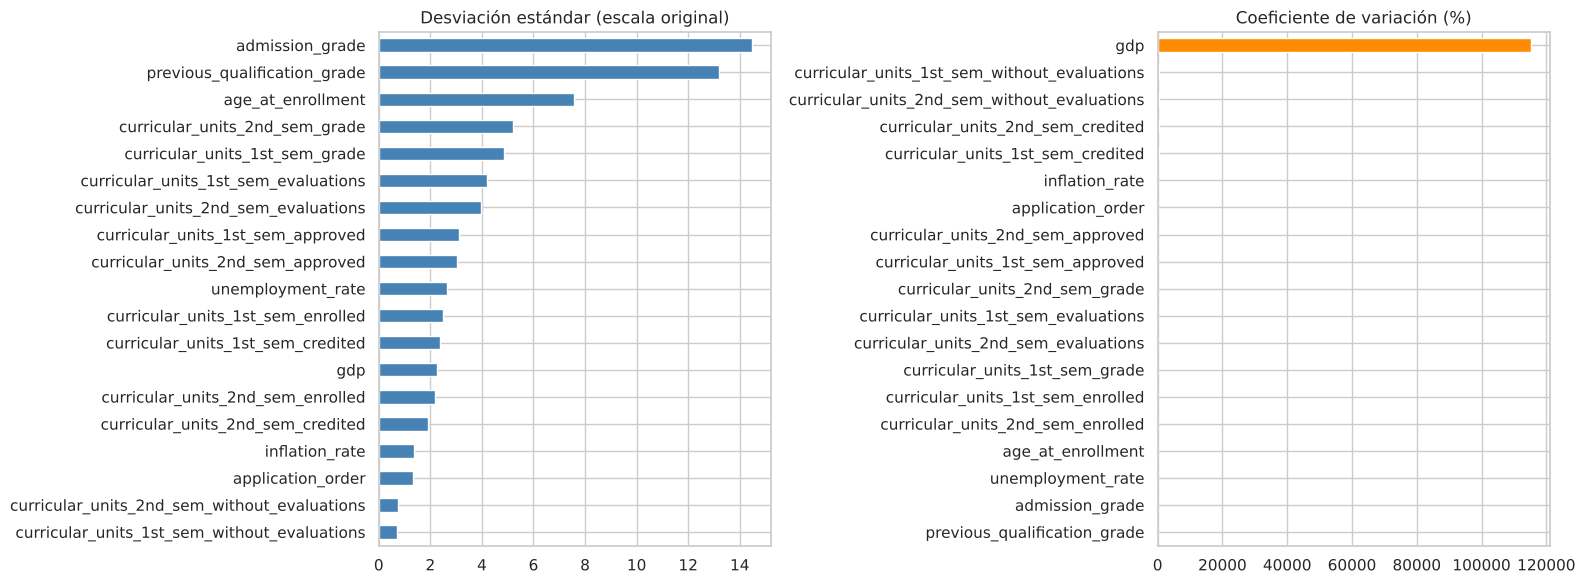

In [10]:
# Desviación estándar comparativa (en escala original y normalizada por la media)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
desc["std"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Desviación estándar (escala original)")
desc["cv_%"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Coeficiente de variación (%)")
plt.tight_layout(); plt.show()

## 1.7 Variable objetivo (`target`)

,estudiantes,porcentaje
target,,
Graduate,2209,49.930
Dropout,1421,32.120
Enrolled,794,17.950


Razón de desbalance (mayoritaria / minoritaria): 2.78


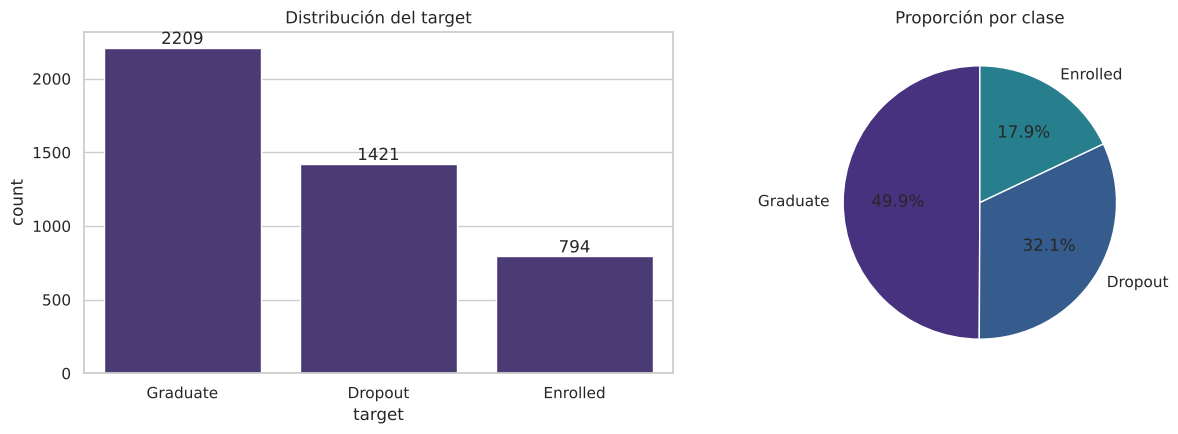

In [11]:
conteo = df[TARGET].value_counts()
resumen_target = pd.DataFrame({"estudiantes": conteo, "porcentaje": (df[TARGET].value_counts(normalize=True) * 100).round(2)})
display(resumen_target)
print(f"Razón de desbalance (mayoritaria / minoritaria): {conteo.max() / conteo.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x=TARGET, order=conteo.index, ax=axes[0])
axes[0].bar_label(axes[0].containers[0]); axes[0].set_title("Distribución del target")
axes[1].pie(conteo, labels=conteo.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Proporción por clase")
plt.tight_layout(); plt.show()

## 1.8 Histogramas de las variables numéricas

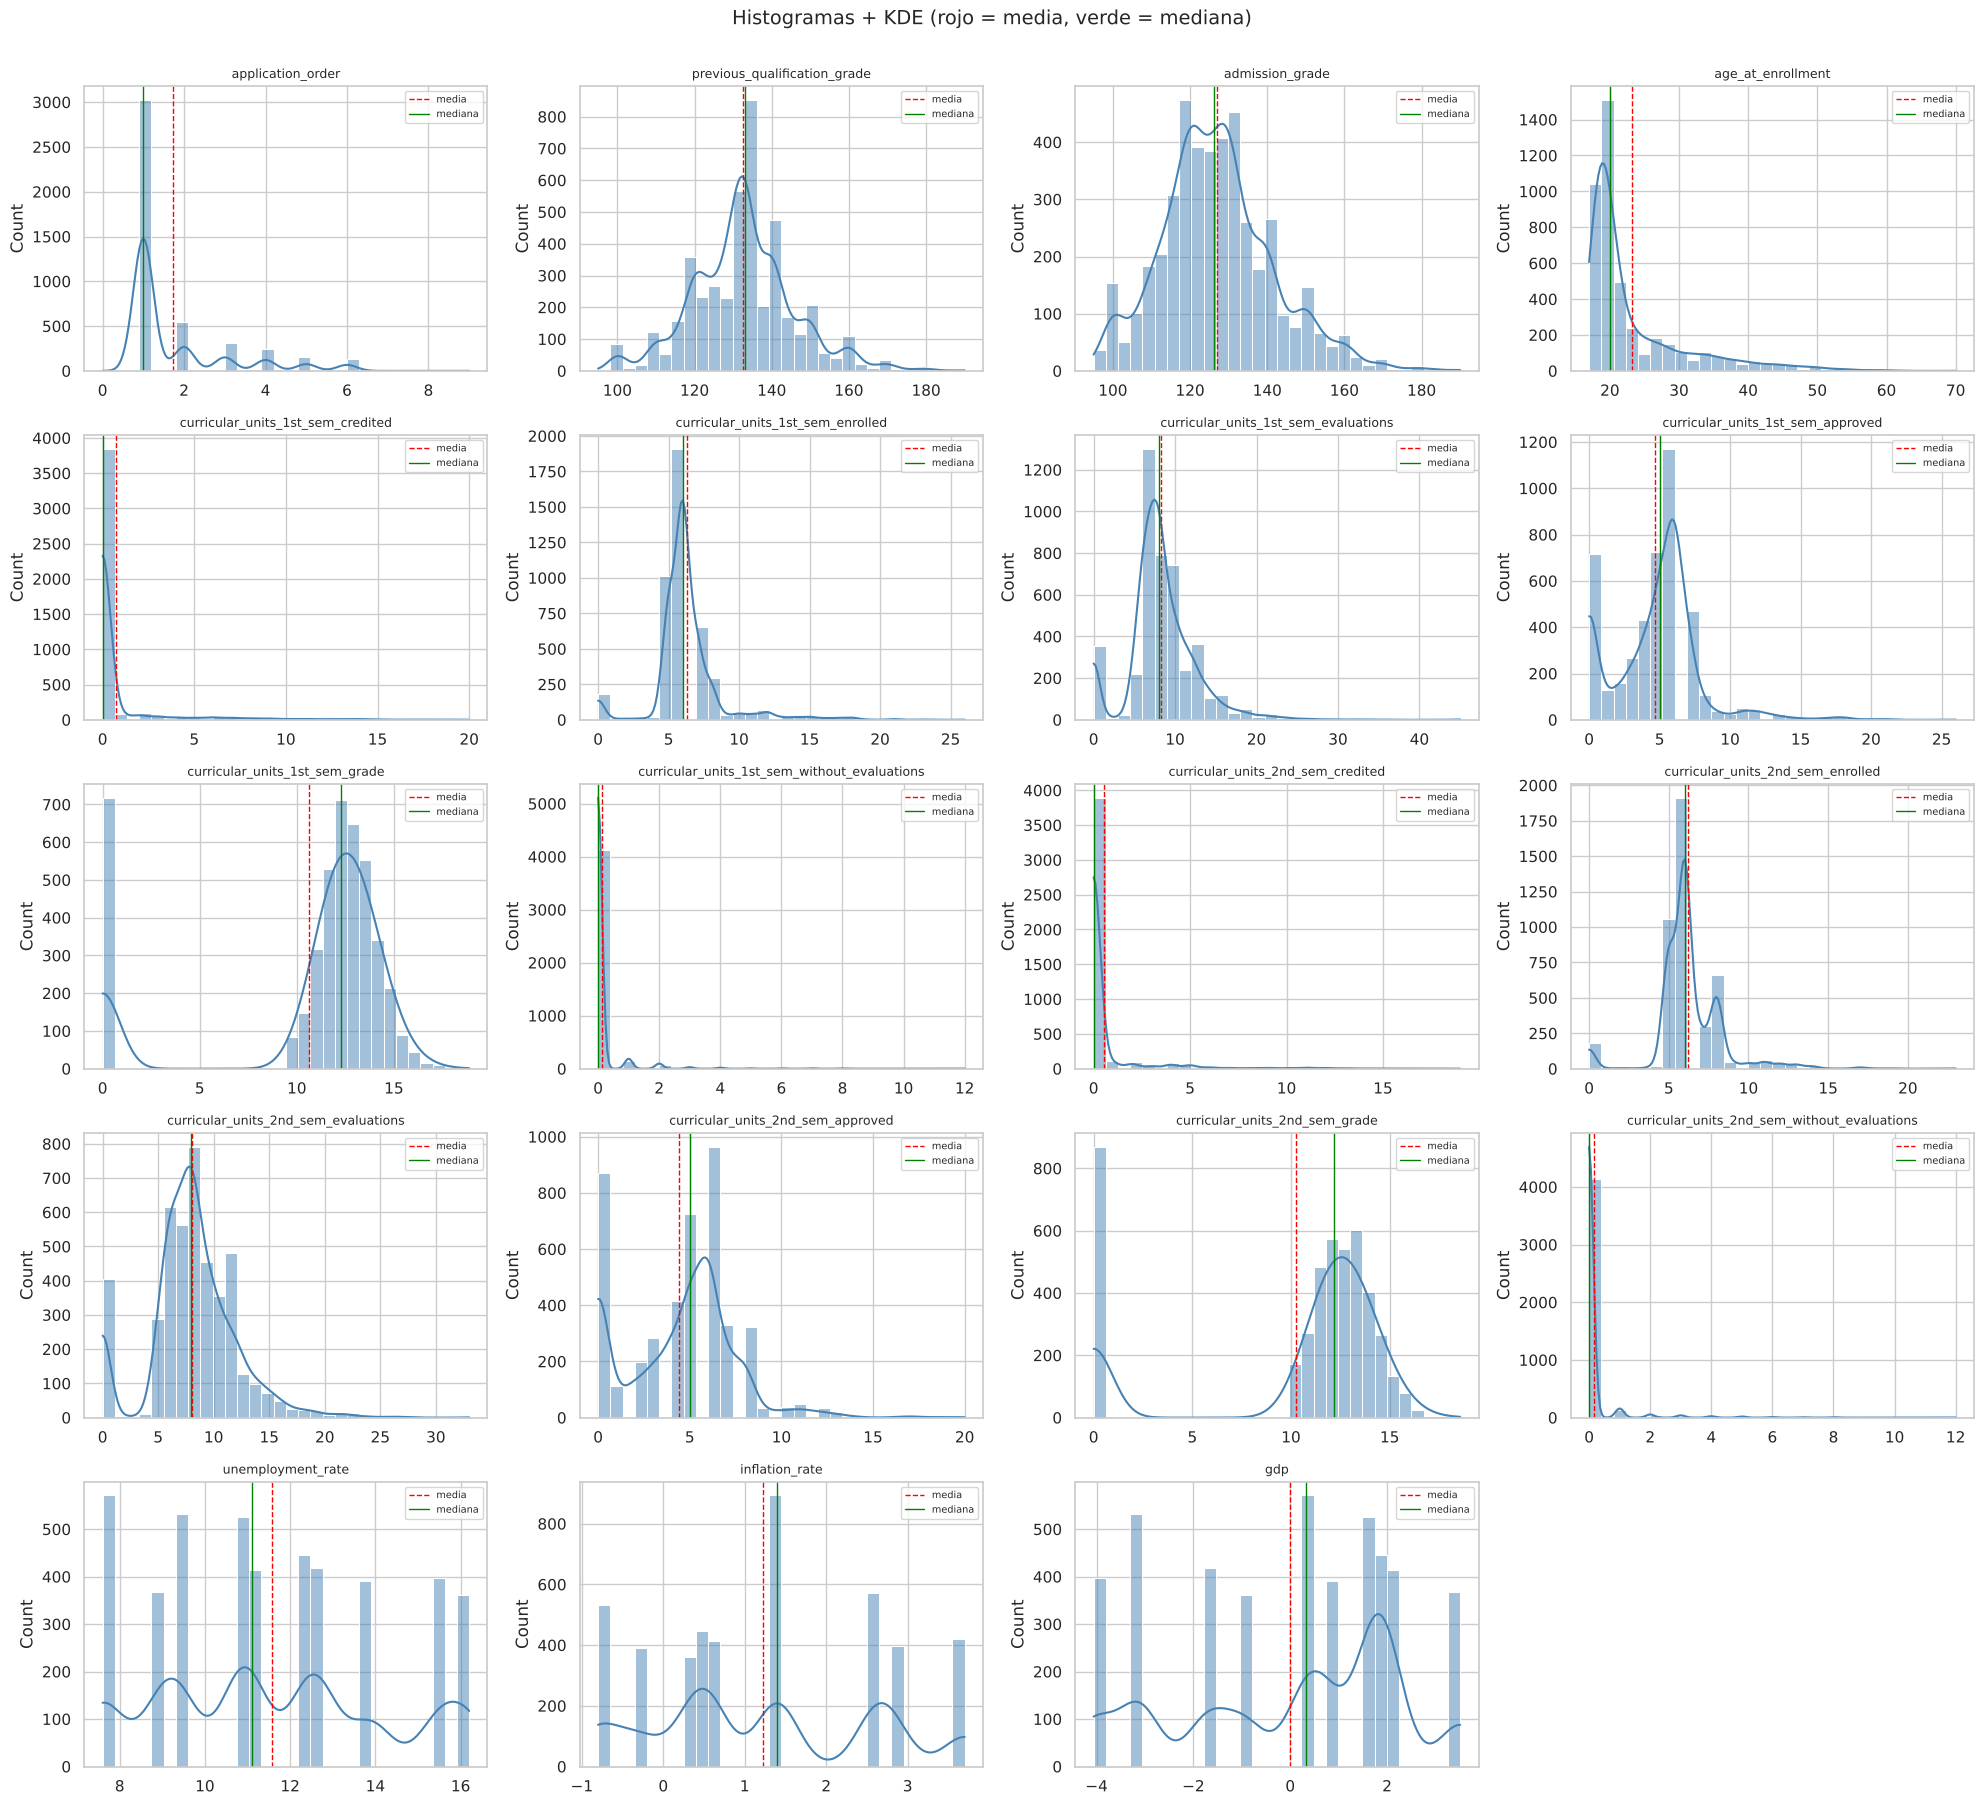

In [12]:
def crear_grilla(n, ncols=4, w=5, h=3.6):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.array(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes


fig, axes = crear_grilla(len(NUM_COLS))
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(df[c], kde=True, ax=ax, color="steelblue", bins=30)
    ax.axvline(df[c].mean(), color="red", ls="--", lw=1, label="media")
    ax.axvline(df[c].median(), color="green", ls="-", lw=1, label="mediana")
    ax.set_title(c, fontsize=9); ax.set_xlabel(""); ax.legend(fontsize=7)
plt.suptitle("Histogramas + KDE (rojo = media, verde = mediana)", y=1.002, fontsize=14)
plt.tight_layout(); plt.show()

## 1.9 Boxplots y detección de outliers (regla IQR)

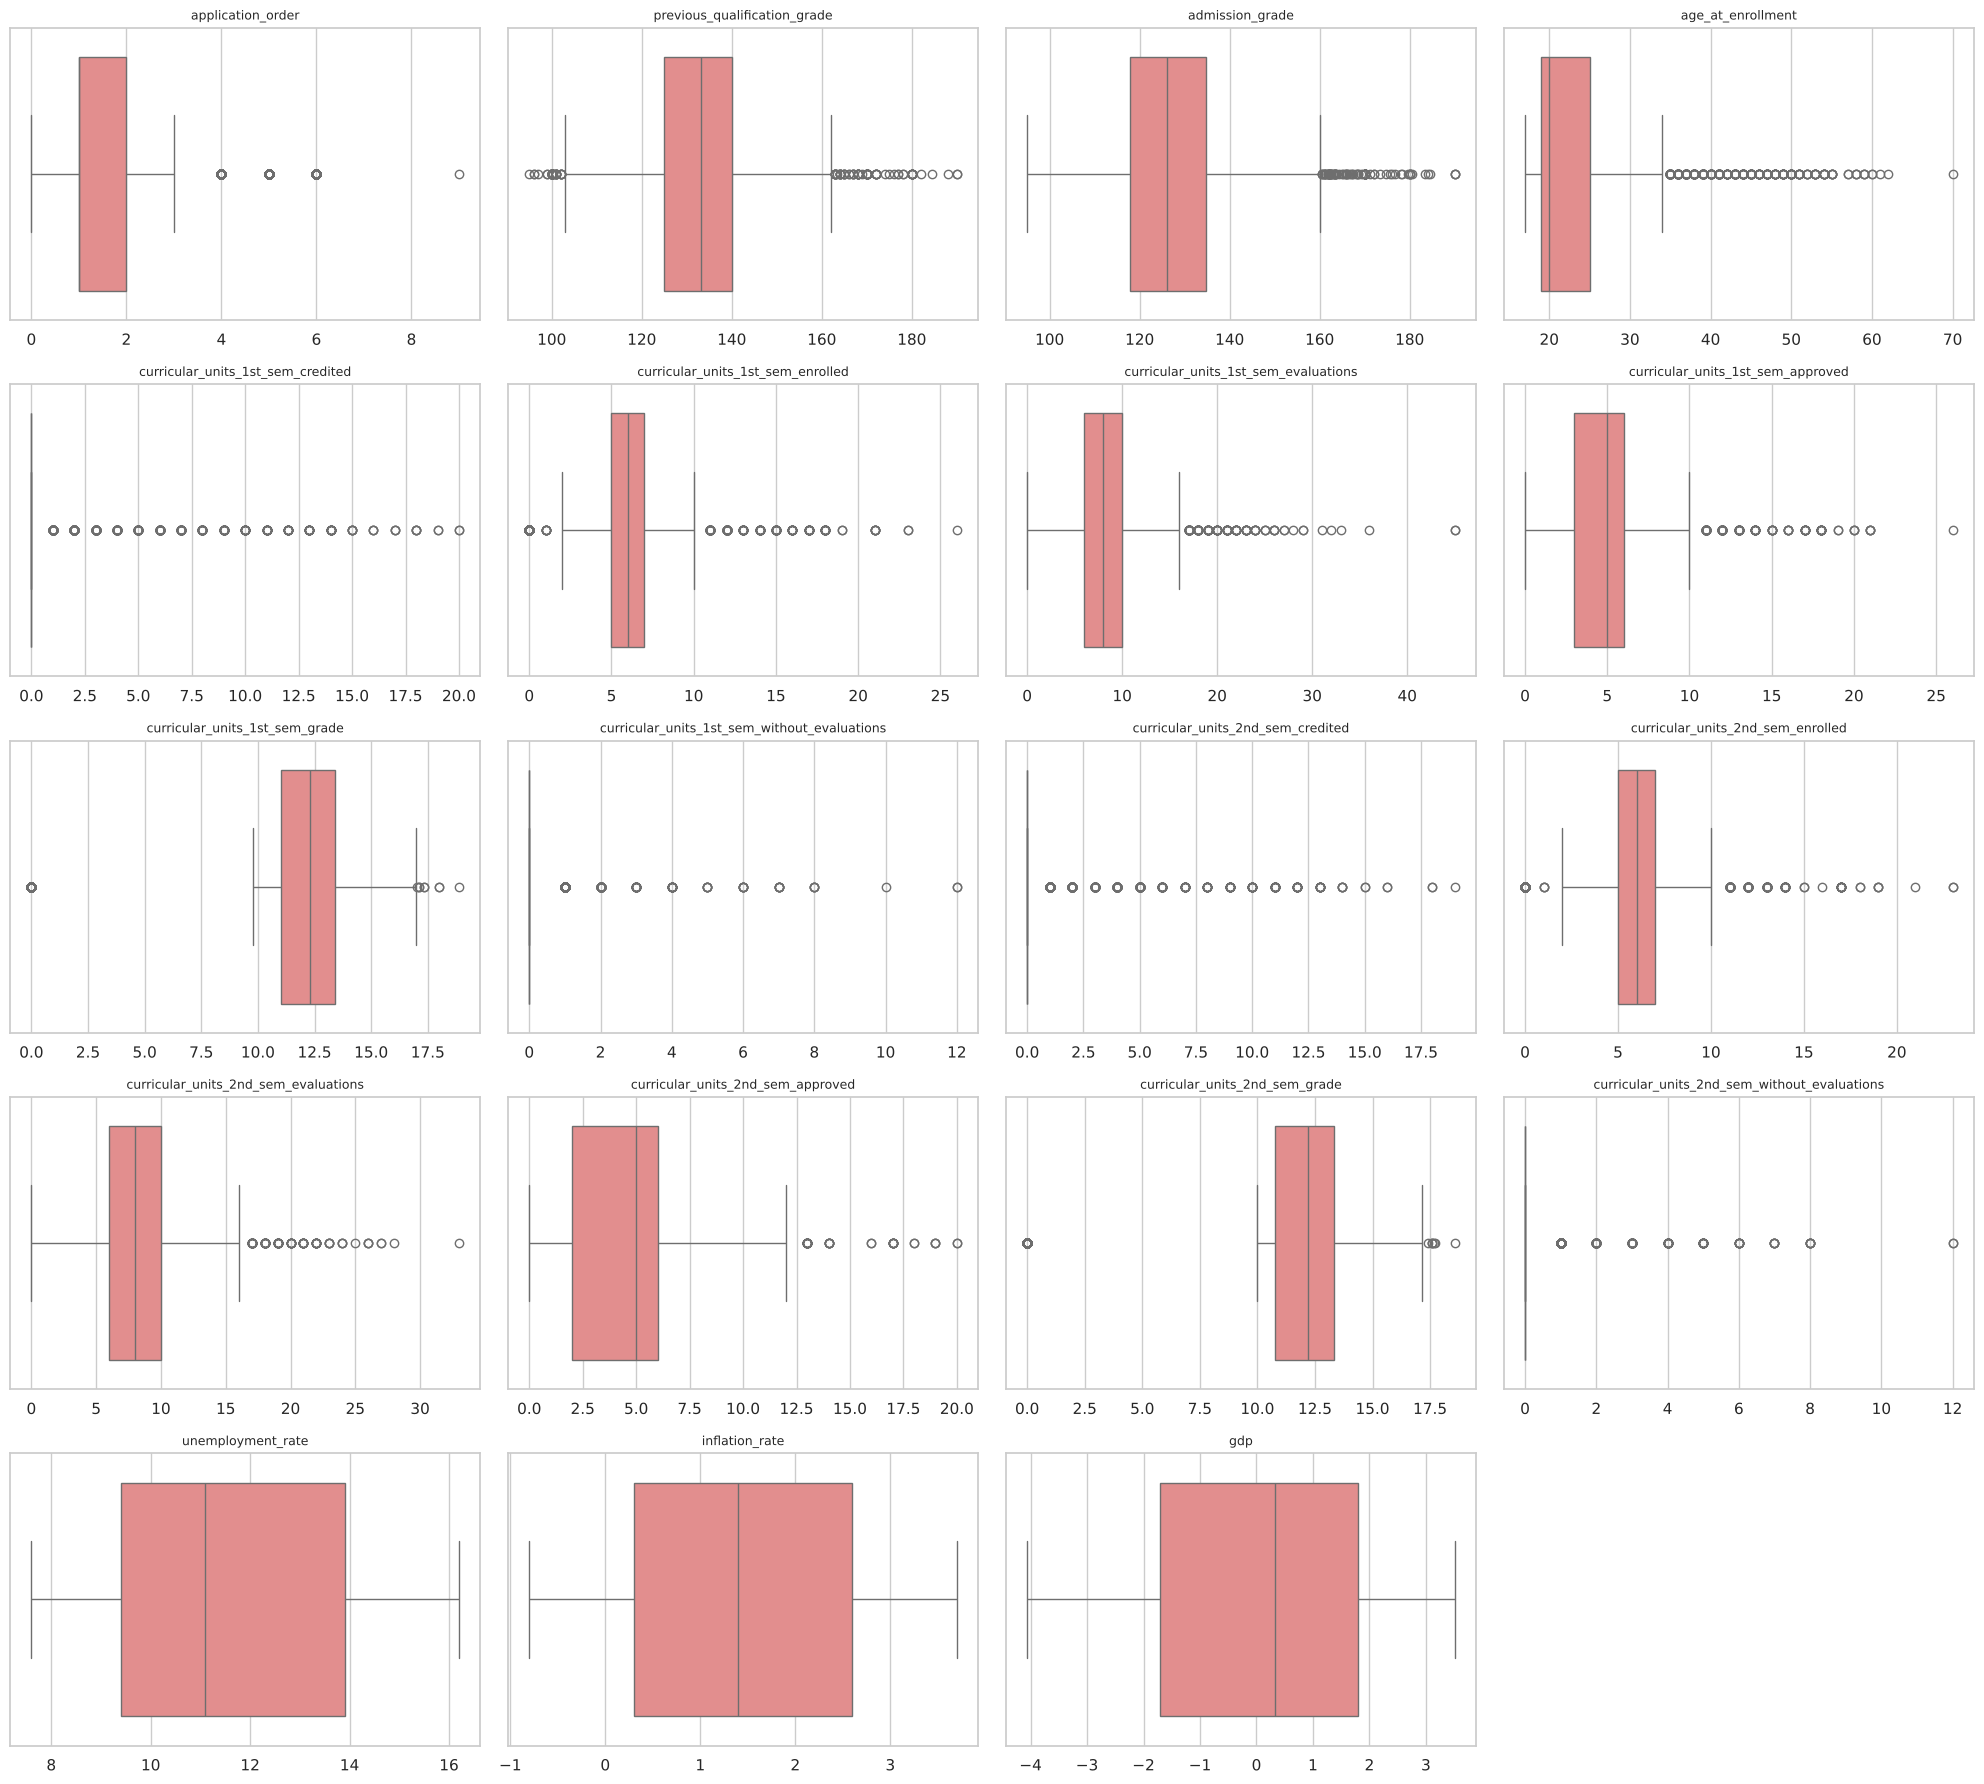

In [13]:
fig, axes = crear_grilla(len(NUM_COLS))
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(x=df[c], ax=ax, color="lightcoral")
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [14]:
def tabla_outliers(data, cols, k=1.5):
    filas = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        li, ls = q1 - k * iqr, q3 + k * iqr
        n = int(((data[c] < li) | (data[c] > ls)).sum())
        filas.append({"variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "lim_inf": li, "lim_sup": ls,
                      "n_outliers": n, "pct_outliers": round(n / len(data) * 100, 2)})
    return pd.DataFrame(filas).set_index("variable").sort_values("pct_outliers", ascending=False)


display(tabla_outliers(df, NUM_COLS))

,Q1,Q3,IQR,lim_inf,lim_sup,n_outliers,pct_outliers
variable,,,,,,,
curricular_units_2nd_sem_grade,10.750,13.333,2.583,6.875,17.208,877,19.820
curricular_units_1st_sem_grade,11.000,13.400,2.400,7.400,17.000,726,16.410
curricular_units_1st_sem_credited,0.000,0.000,0.000,0.000,0.000,577,13.040
application_order,1.000,2.000,1.000,-0.500,3.500,541,12.230
curricular_units_2nd_sem_credited,0.000,0.000,0.000,0.000,0.000,530,11.980
age_at_enrollment,19.000,25.000,6.000,10.000,34.000,441,9.970
curricular_units_1st_sem_enrolled,5.000,7.000,2.000,2.000,10.000,424,9.580
curricular_units_2nd_sem_enrolled,5.000,7.000,2.000,2.000,10.000,369,8.340
curricular_units_1st_sem_without_evaluations,0.000,0.000,0.000,0.000,0.000,294,6.650


## 1.10 Variables binarias y categóricas

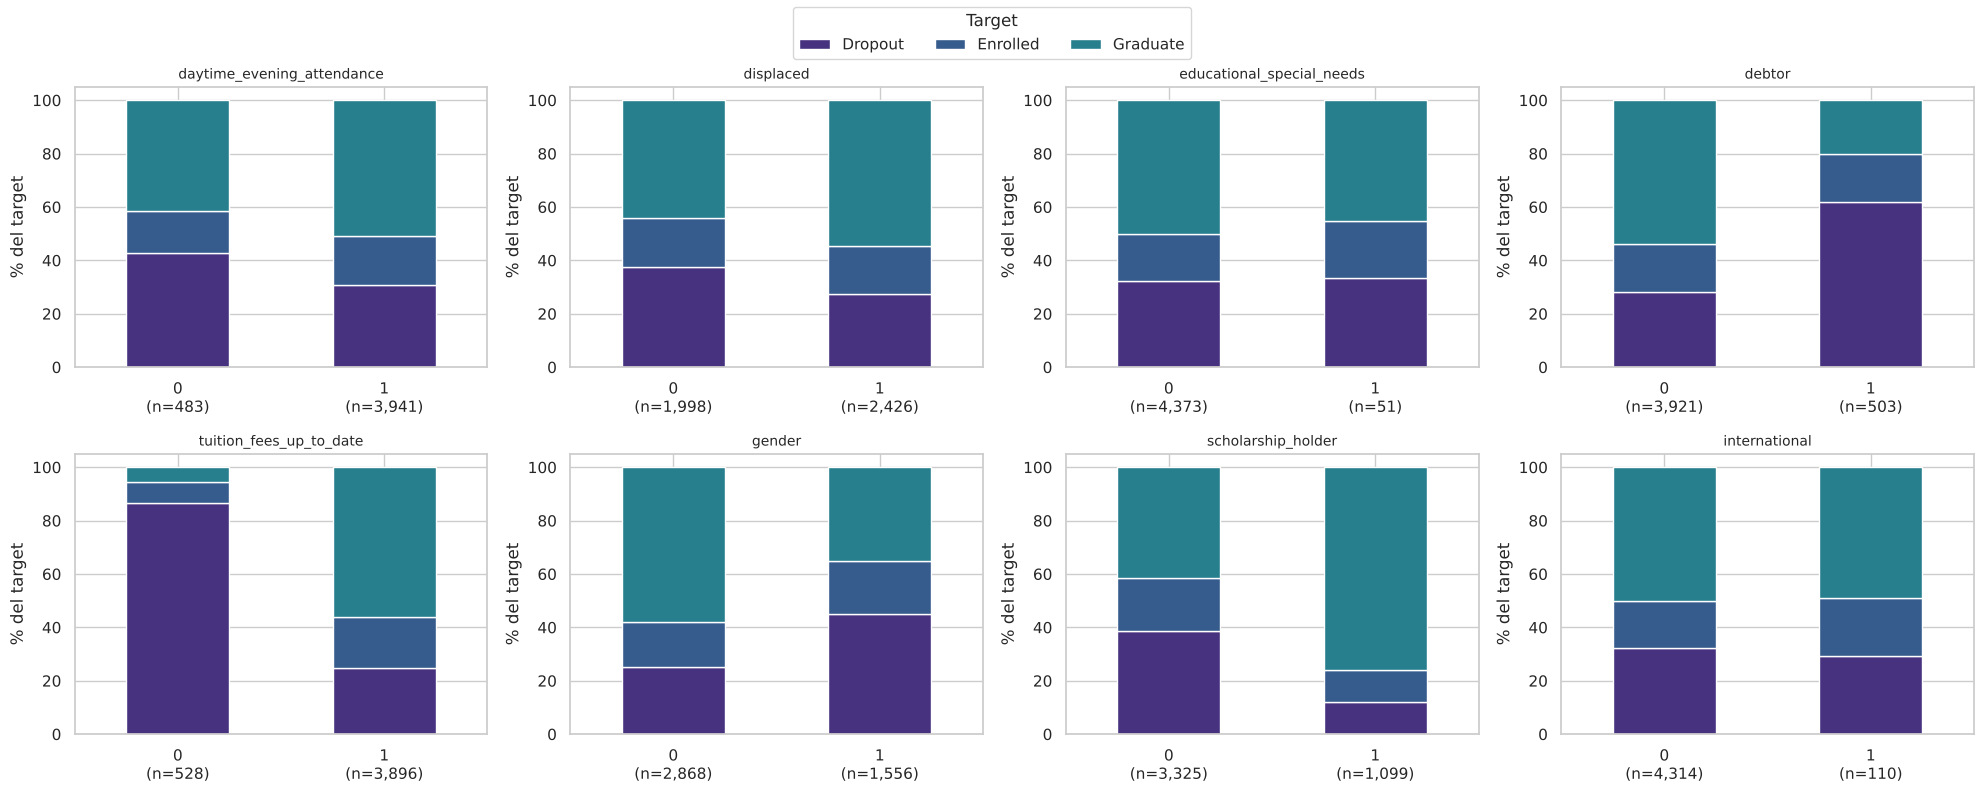

In [15]:
# Binarias: distribución y composición del target dentro de cada categoría (% por fila)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), BINARY_COLS):
    ct = pd.crosstab(df[c], df[TARGET], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, ax=ax, rot=0, legend=False)
    n = df[c].value_counts().sort_index()
    ax.set_xticklabels([f"{i}\n(n={n[i]:,})" for i in ct.index])
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("% del target")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, title="Target")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

In [16]:
# Cardinalidad de las categóricas codificadas y frecuencia de sus categorías principales
for c in CAT_COLS:
    vc = df[c].value_counts()
    print(f"{c:<26} {vc.size:>3} categorías | top-3: " + ", ".join(f"{k} ({v / len(df) * 100:.1f}%)" for k, v in vc.head(3).items()))

marital_status               6 categorías | top-3: 1 (88.6%), 2 (8.6%), 4 (2.1%)
application_mode            18 categorías | top-3: 1 (38.6%), 17 (19.7%), 39 (17.7%)
course                      17 categorías | top-3: 9500 (17.3%), 9147 (8.6%), 9238 (8.0%)
previous_qualification      17 categorías | top-3: 1 (84.0%), 39 (5.0%), 19 (3.7%)
nationality                 21 categorías | top-3: 1 (97.5%), 41 (0.9%), 26 (0.3%)
mothers_qualification       29 categorías | top-3: 1 (24.2%), 37 (22.8%), 19 (21.5%)
fathers_qualification       34 categorías | top-3: 37 (27.3%), 19 (21.9%), 1 (20.4%)
mothers_occupation          32 categorías | top-3: 9 (35.6%), 4 (18.5%), 5 (12.0%)
fathers_occupation          46 categorías | top-3: 9 (22.8%), 7 (15.1%), 5 (11.7%)


,n,tasa_desercion,tasa_graduacion
33 · Tecnologías de Producción de Biocombustibles,12,66.667,8.333
9130 · Equinocultura,141,55.319,29.787
9119 · Ingeniería Informática,170,54.118,8.235
9991 · Gestión (nocturno),268,50.746,29.104
9853 · Educación Básica,192,44.271,29.688
9003 · Agronomía,210,40.952,41.429
9556 · Higiene Oral,86,38.372,41.860
171 · Diseño de Animación y Multimedia,215,38.140,44.651
9254 · Turismo,252,38.095,45.635
9670 · Gestión de Publicidad y Marketing,268,35.448,46.642


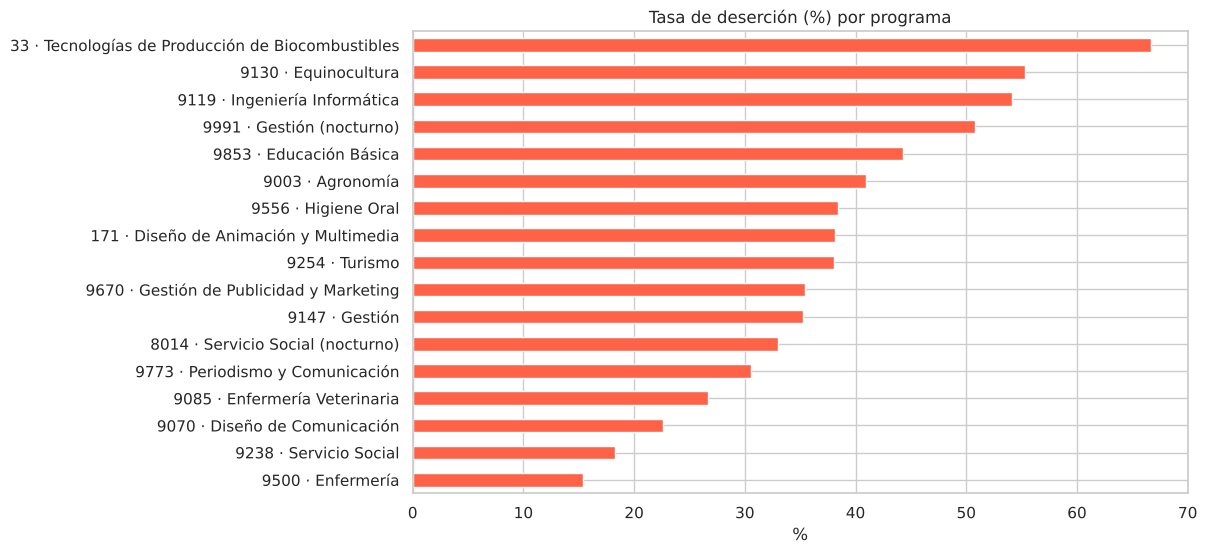

In [ ]:
# Tasa de deserción por programa académico (course)
g = df.groupby("course")[TARGET].agg(
    n="count",
    tasa_desercion=lambda s: (s == "Dropout").mean() * 100,
    tasa_graduacion=lambda s: (s == "Graduate").mean() * 100,
).sort_values("tasa_desercion", ascending=False)
#  se muestra el nombre del programa además del código
g.index = [f"{c} · {dd.code_label('course', c)}" for c in g.index]
display(g)

g["tasa_desercion"].sort_values().plot.barh(figsize=(10, 6), color="tomato")
plt.title("Tasa de deserción (%) por programa"); plt.xlabel("%"); plt.show()

## 1.11 Variables numéricas vs. target

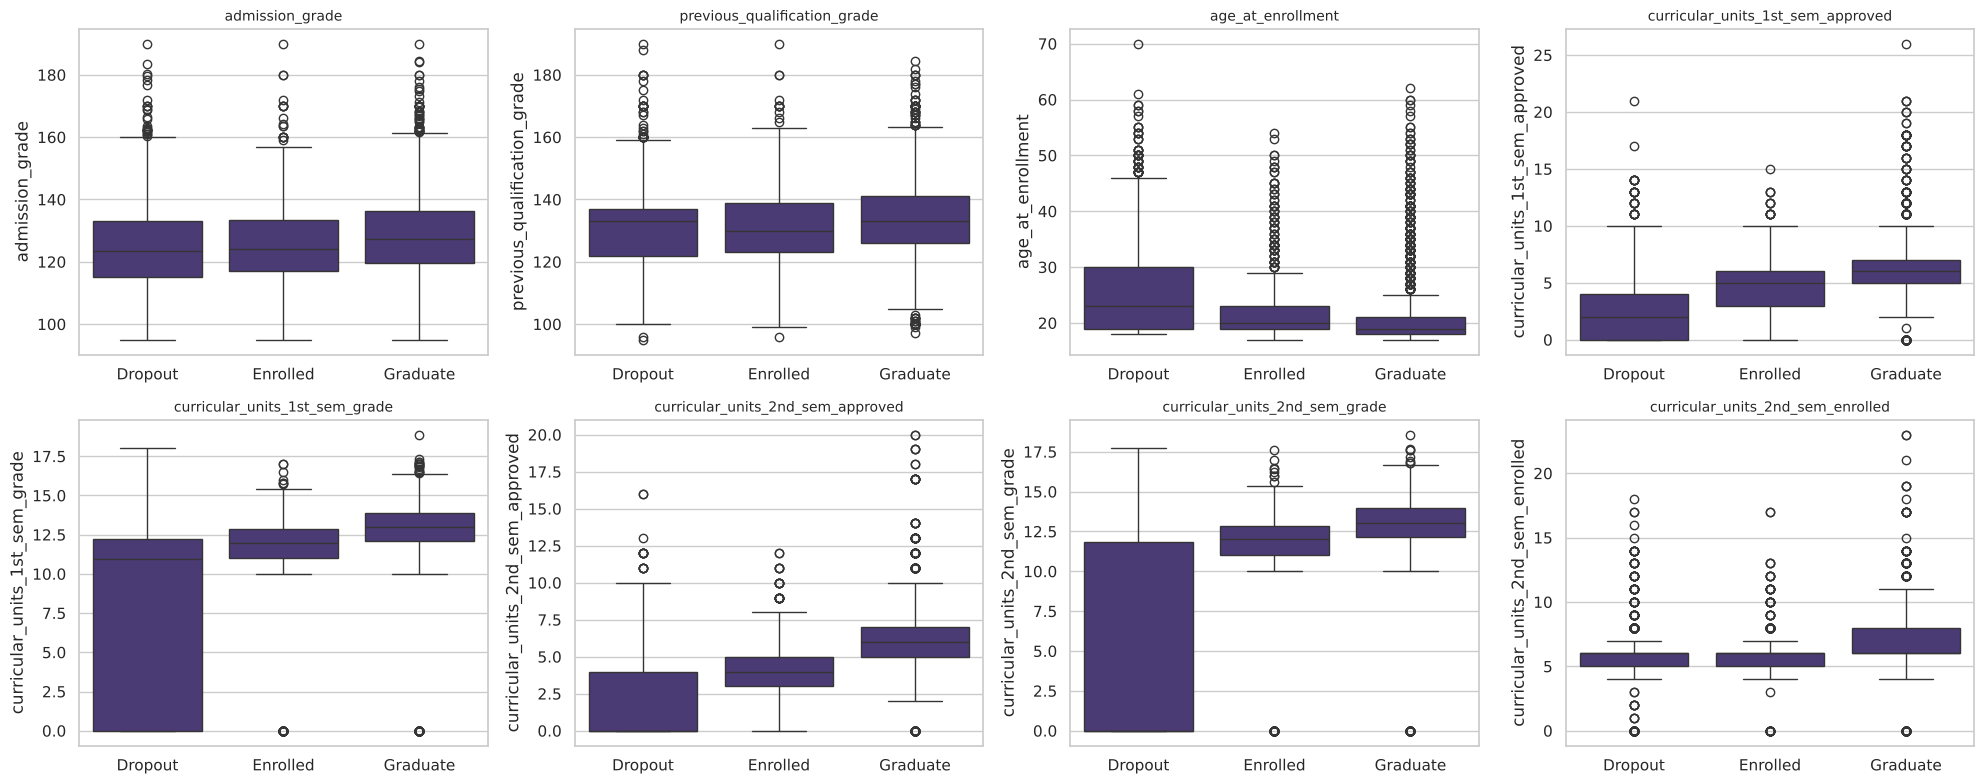

target                                  Dropout  Enrolled  Graduate
admission_grade                   mean  124.960   125.530   128.790
                                  std    15.130    13.790    14.070
previous_qualification_grade      mean  131.110   131.210   134.080
                                  std    12.870    12.870    13.340
age_at_enrollment                 mean   26.070    22.370    21.780
                                  std     8.700     6.300     6.690
curricular_units_1st_sem_approved mean    2.550     4.320     6.230
                                  std     2.860     2.290     2.580
curricular_units_1st_sem_grade    mean    7.260    11.130    12.640
                                  std     6.030     3.680     2.700
curricular_units_2nd_sem_approved mean    1.940     4.060     6.180
                                  std     2.570     2.180     2.270
curricular_units_2nd_sem_grade    mean    5.900    11.120    12.700
                                  std     6.120     3.600     2.690
curricular_units_2nd_sem_enrolled mean    5.780     5.940     6.630
                                  std     2.110     1.830     2.300

In [18]:
CLAVES = ["admission_grade", "previous_qualification_grade", "age_at_enrollment",
          "curricular_units_1st_sem_approved", "curricular_units_1st_sem_grade",
          "curricular_units_2nd_sem_approved", "curricular_units_2nd_sem_grade",
          "curricular_units_2nd_sem_enrolled"]
CLAVES = [c for c in CLAVES if c in df.columns]
orden = ["Dropout", "Enrolled", "Graduate"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), CLAVES):
    sns.boxplot(data=df, x=TARGET, y=c, order=orden, ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

display(df.groupby(TARGET)[CLAVES].agg(["mean", "std"]).round(2).T)

## 1.12 Correlaciones
- **Pearson** entre variables numéricas → detecta multicolinealidad.
- Correlación de cada variable (numéricas + binarias) con `Dropout` y con `Graduate`.

> ⚠️ Las categóricas codificadas (curso, ocupación, etc.) son **códigos nominales**: su correlación numérica no tiene sentido, por eso se excluyen.

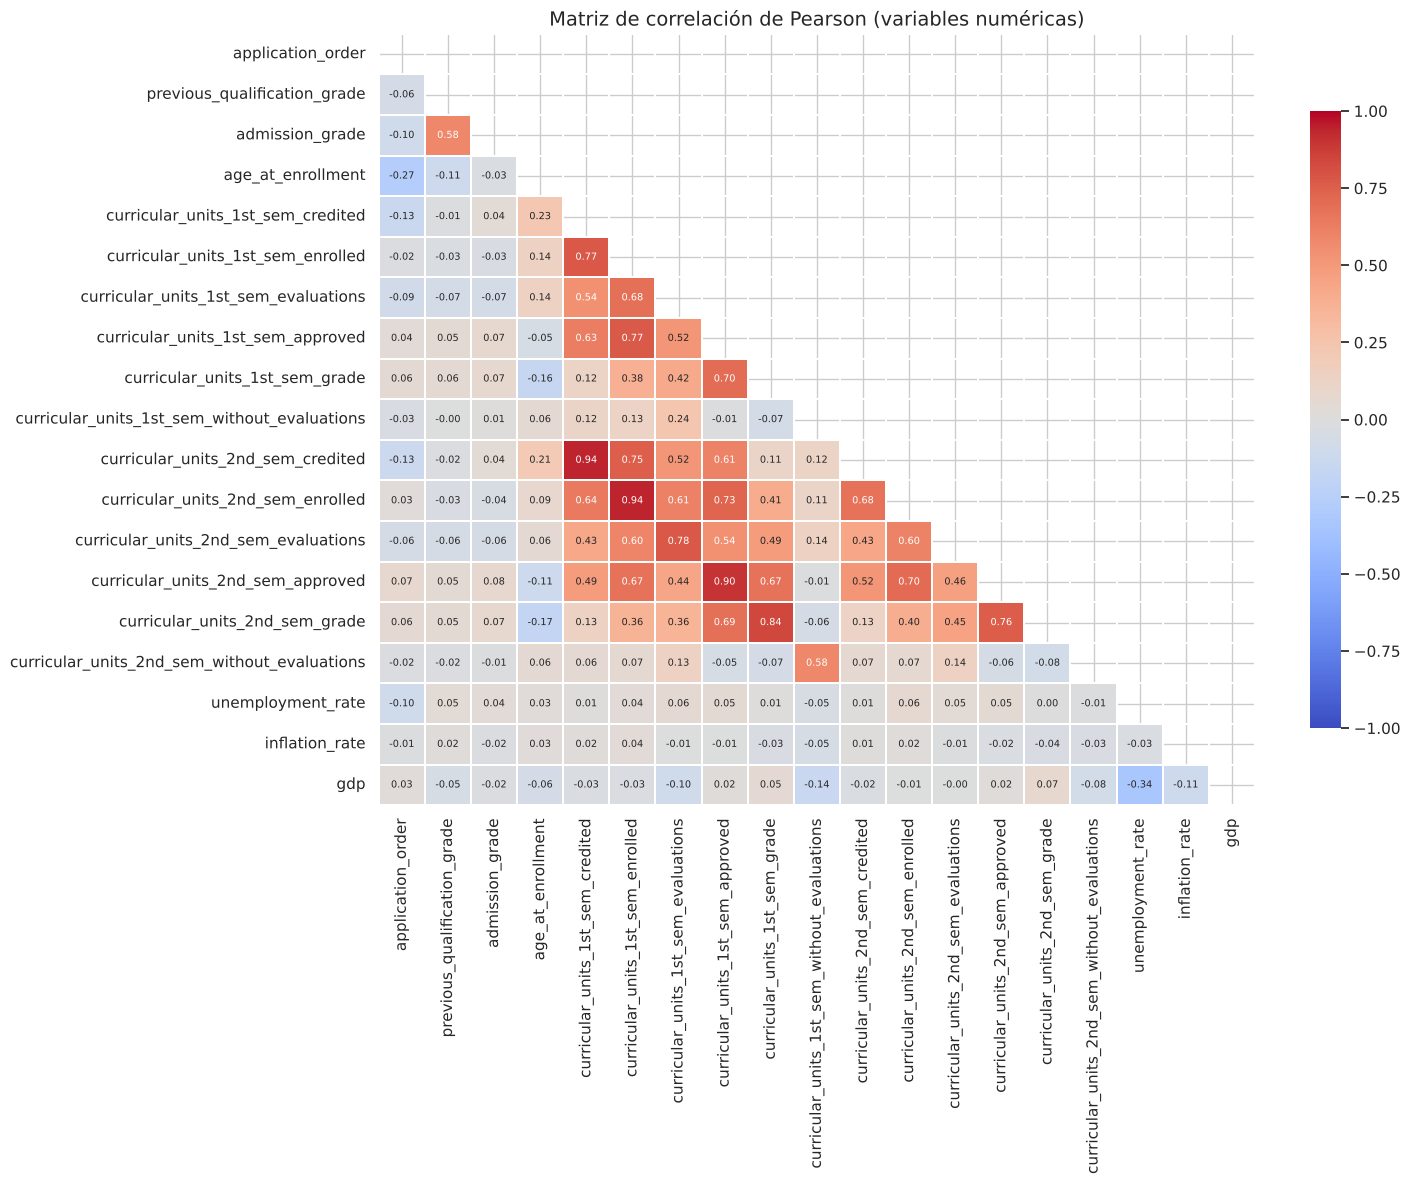

In [19]:
corr = df[NUM_COLS].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(15, 12))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.3, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación de Pearson (variables numéricas)", fontsize=14)
plt.tight_layout(); plt.show()

In [20]:
# Pares con alta correlación (posible multicolinealidad)
pares = corr.where(~mask).stack().reset_index()
pares.columns = ["var1", "var2", "r"]
pares["abs_r"] = pares["r"].abs()
altos = pares[pares["abs_r"] >= 0.7].sort_values("abs_r", ascending=False)
print(f"Pares con |r| >= 0.70: {len(altos)}")
display(altos.drop(columns="abs_r"))

Pares con |r| >= 0.70: 11


,var1,var2,r
194,curricular_units_2nd_sem_credited,curricular_units_1st_sem_credited,0.945
214,curricular_units_2nd_sem_enrolled,curricular_units_1st_sem_enrolled,0.943
254,curricular_units_2nd_sem_approved,curricular_units_1st_sem_approved,0.904
274,curricular_units_2nd_sem_grade,curricular_units_1st_sem_grade,0.837
234,curricular_units_2nd_sem_evaluations,curricular_units_1st_sem_evaluations,0.779
99,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_credited,0.774
138,curricular_units_1st_sem_approved,curricular_units_1st_sem_enrolled,0.769
279,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_approved,0.761
195,curricular_units_2nd_sem_credited,curricular_units_1st_sem_enrolled,0.754
216,curricular_units_2nd_sem_enrolled,curricular_units_1st_sem_approved,0.734


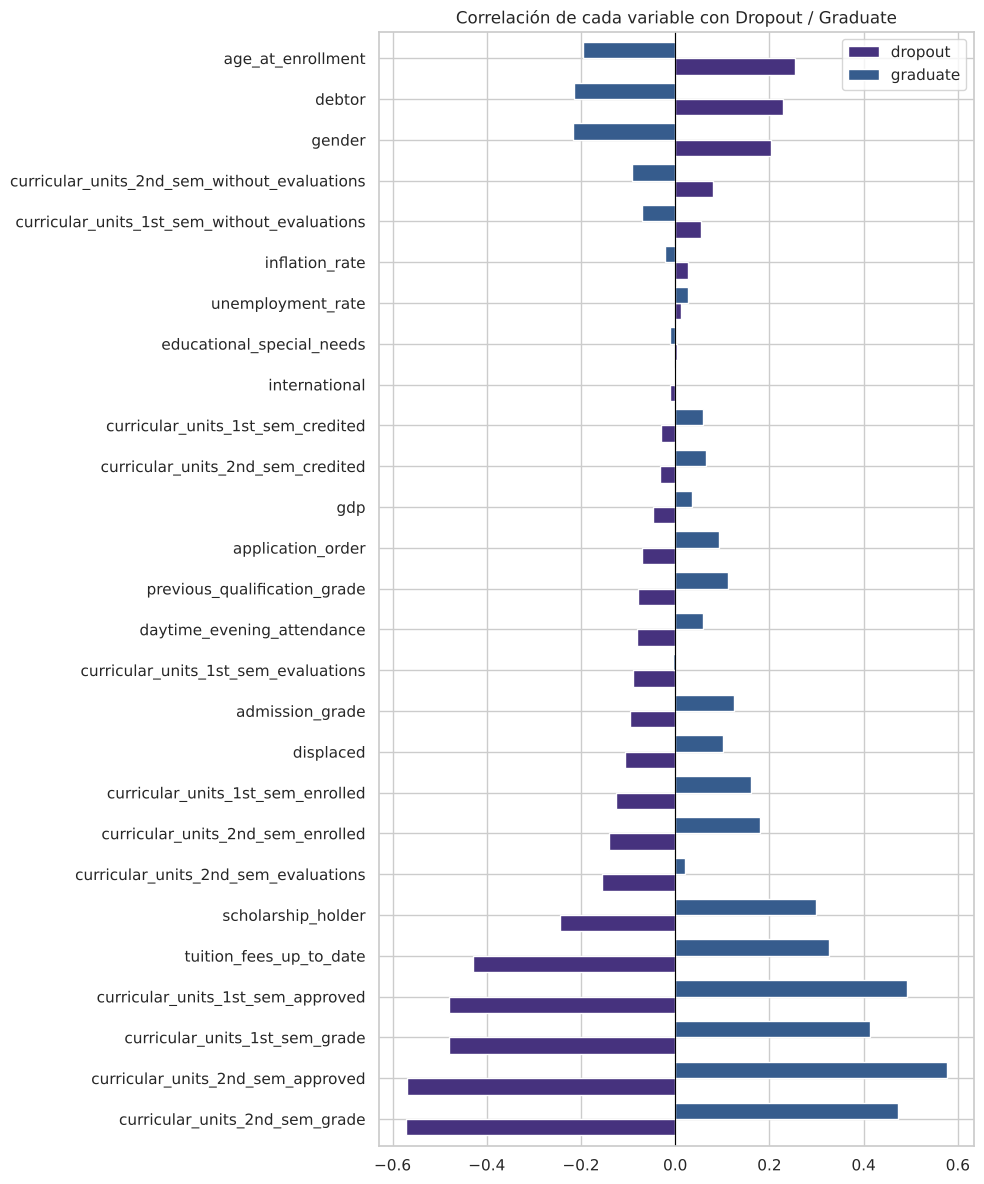

Top 8 asociadas a mayor deserción:


,dropout
age_at_enrollment,0.254
debtor,0.229
gender,0.204
curricular_units_2nd_sem_without_evaluations,0.080
curricular_units_1st_sem_without_evaluations,0.054
inflation_rate,0.028
unemployment_rate,0.013
educational_special_needs,0.003


In [21]:
# Correlación con el target (one-vs-rest)
y_drop = (df[TARGET] == "Dropout").astype(int)
y_grad = (df[TARGET] == "Graduate").astype(int)
cols_corr = NUM_COLS + BINARY_COLS

corr_t = pd.DataFrame({"dropout": df[cols_corr].corrwith(y_drop),
                       "graduate": df[cols_corr].corrwith(y_grad)}).sort_values("dropout")

corr_t.plot.barh(figsize=(10, 12), width=0.8)
plt.axvline(0, color="black", lw=0.8)
plt.title("Correlación de cada variable con Dropout / Graduate"); plt.tight_layout(); plt.show()

print("Top 8 asociadas a mayor deserción:")
display(corr_t["dropout"].sort_values(ascending=False).head(8).to_frame())

## 1.13 Chequeo de consistencia lógica
Reglas de negocio que deberían cumplirse:
- **Duras** (error seguro): notas fuera de rango (ingreso y previa en [0, 200]; notas semestrales en [0, 20]), valores negativos en conteos.
- **Blandas** (sospechosas, no necesariamente error): más aprobadas que inscritas, nota > 0 sin materias inscritas, etc.

In [22]:
def reglas_consistencia(d):
    s1, s2 = "curricular_units_1st_sem_", "curricular_units_2nd_sem_"
    duras = {
        "admission_grade fuera de [0, 200]": ~d["admission_grade"].between(0, 200),
        "previous_qualification_grade fuera de [0, 200]": ~d["previous_qualification_grade"].between(0, 200),
        "nota 1er sem fuera de [0, 20]": ~d[s1 + "grade"].between(0, 20),
        "nota 2do sem fuera de [0, 20]": ~d[s2 + "grade"].between(0, 20),
        "edad al matricular < 14": d["age_at_enrollment"] < 14,
        "conteos curriculares negativos": (d[[c for c in d.columns if c.startswith("curricular_units")
                                               and "grade" not in c]] < 0).any(axis=1),
    }
    blandas = {
        "1er sem: aprobadas > inscritas": d[s1 + "approved"] > d[s1 + "enrolled"],
        "2do sem: aprobadas > inscritas": d[s2 + "approved"] > d[s2 + "enrolled"],
        "1er sem: nota > 0 sin materias inscritas": (d[s1 + "grade"] > 0) & (d[s1 + "enrolled"] == 0),
        "2do sem: nota > 0 sin materias inscritas": (d[s2 + "grade"] > 0) & (d[s2 + "enrolled"] == 0),
        "1er sem: inscritas > 0 y nota == 0": (d[s1 + "enrolled"] > 0) & (d[s1 + "grade"] == 0),
        "2do sem: inscritas > 0 y nota == 0": (d[s2 + "enrolled"] > 0) & (d[s2 + "grade"] == 0),
        "sin materias inscritas en ambos semestres": (d[s1 + "enrolled"] == 0) & (d[s2 + "enrolled"] == 0),
    }
    return duras, blandas


duras, blandas = reglas_consistencia(df)
tabla_reglas = pd.DataFrame(
    [{"tipo": "dura", "regla": k, "filas": int(v.sum())} for k, v in duras.items()] +
    [{"tipo": "blanda", "regla": k, "filas": int(v.sum())} for k, v in blandas.items()])
tabla_reglas["pct"] = (tabla_reglas["filas"] / len(df) * 100).round(2)
display(tabla_reglas)

,tipo,regla,filas,pct
0,dura,"admission_grade fuera de [0, 200]",0,0.000
1,dura,"previous_qualification_grade fuera de [0, 200]",0,0.000
2,dura,"nota 1er sem fuera de [0, 20]",0,0.000
3,dura,"nota 2do sem fuera de [0, 20]",0,0.000
4,dura,edad al matricular < 14,0,0.000
5,dura,conteos curriculares negativos,0,0.000
6,blanda,1er sem: aprobadas > inscritas,0,0.000
7,blanda,2do sem: aprobadas > inscritas,0,0.000
8,blanda,1er sem: nota > 0 sin materias inscritas,0,0.000
9,blanda,2do sem: nota > 0 sin materias inscritas,0,0.000


In [ ]:
#  Verificación: las reglas blandas del cuaderno coinciden con las del pipeline (src/data_loader.soft_rule_flags)
flag_nb = pd.concat(blandas.values(), axis=1).any(axis=1)
assert (flag_nb == soft_rule_flags(df)).all()
print(f"✅ Casos marcados por reglas blandas: {int(flag_nb.sum())} ({flag_nb.mean() * 100:.1f} %), idénticos en cuaderno y pipeline")

✅ Casos marcados por reglas blandas: 912 (20.6 %), idénticos en cuaderno y pipeline


## 1.14 Resumen automático de hallazgos del EDA

In [24]:
print("=" * 70)
print("RESUMEN DEL EDA")
print("=" * 70)
print(f"• Registros: {len(df):,} | Variables: {len(FEATURES)} (+ target)")
print(f"• Nulos totales: {total_nulos} | Duplicados exactos: {n_dup}")
print(f"• Clases del target: " + ", ".join(f"{k} {v:.1f}%" for k, v in (df[TARGET].value_counts(normalize=True) * 100).items()))
print(f"• Variables numéricas muy sesgadas (|skew|>1): {int((desc['asimetria'].abs() > 1).sum())} de {len(NUM_COLS)}")
print(f"• Variables con outliers IQR: {int((tabla_outliers(df, NUM_COLS)['n_outliers'] > 0).sum())} de {len(NUM_COLS)}")
print(f"• Pares muy correlacionados (|r|>=0.7): {len(altos)}")
print(f"• Violaciones de reglas duras: {int(tabla_reglas.query('tipo == \"dura\"')['filas'].sum())}")
print(f"• Casos sospechosos (reglas blandas): {int(tabla_reglas.query('tipo == \"blanda\"')['filas'].sum())} (suma, una fila puede repetirse)")

RESUMEN DEL EDA
• Registros: 4,424 | Variables: 36 (+ target)
• Nulos totales: 0 | Duplicados exactos: 0
• Clases del target: Graduate 49.9%, Dropout 32.1%, Enrolled 17.9%
• Variables numéricas muy sesgadas (|skew|>1): 9 de 19
• Variables con outliers IQR: 16 de 19
• Pares muy correlacionados (|r|>=0.7): 11
• Violaciones de reglas duras: 0
• Casos sospechosos (reglas blandas): 1408 (suma, una fila puede repetirse)


In [25]:
# Cifras complementarias usadas en las conclusiones
y_drop_ = df[TARGET] == "Dropout"
apr2 = df["curricular_units_2nd_sem_approved"]
print(f"Deserción con 0 unidades aprobadas en 2.º sem: {y_drop_[apr2 == 0].mean() * 100:.1f} % | con 4 o más: {y_drop_[apr2 >= 4].mean() * 100:.1f} %")
edad = pd.cut(df["age_at_enrollment"], [0, 19, 24, 29, 100], labels=["≤19", "20–24", "25–29", "≥30"])
display(df.assign(edad=edad).groupby("edad", observed=True)[TARGET].apply(lambda s: (s == "Dropout").mean() * 100).round(1).to_frame("% deserción"))

Deserción con 0 unidades aprobadas en 2.º sem: 83.6 % | con 4 o más: 12.3 %


,% deserción
edad,
≤19,21.000
20–24,28.600
25–29,57.600
≥30,54.100


### 📝 Conclusiones del EDA
1. **Calidad de los datos:** el dataset llega limpio: **0 nulos, 0 duplicados y 0 violaciones de reglas duras** (notas fuera de rango, conteos negativos). Se detectaron **912 estudiantes (≈ 20,6 %) con casos atípicos** (materias inscritas con nota 0, o sin materias en ambos semestres), que se marcan sin eliminar.
2. **Target desbalanceado:** Graduate 49,9 %, Dropout 32,1 %, Enrolled 17,9 % (razón mayoritaria/minoritaria ≈ 2,8). Obliga a usar partición **estratificada**, a tratar el desbalance (pesos de clase) y a usar métricas robustas como macro-F1 en lugar de solo accuracy.
3. **Distribuciones:** 9 de 19 variables numéricas están muy sesgadas (|asimetría| > 1): unidades **sin evaluación**, **créditos reconocidos**, **edad al ingresar**, **orden de la solicitud** y las **notas semestrales** (sesgo negativo, por los estudiantes con nota 0). Las notas de ingreso y previa son aproximadamente simétricas. Los conteos curriculares tienen alta dispersión relativa por la gran cantidad de ceros; el CV de `gdp` e `inflation_rate` no es interpretable porque su media está cerca de 0.
4. **Correlaciones:** la señal más fuerte con la deserción es el rendimiento académico: unidades aprobadas y notas del 2.º semestre (r ≈ −0,57) y del 1.º (r ≈ −0,48), seguidas de matrícula al día (−0,43) y beca (−0,25). Se asocian positivamente la edad al ingresar (0,25), la deuda (0,23) y el género codificado como 1 (0,20). Hay **multicolinealidad** fuerte entre variables del 1.er y 2.º semestre (11 pares con |r| ≥ 0,7; máx. 0,945), lo que favorece modelos regularizados o de árboles.
5. **Outliers:** 16 de 19 variables tienen valores fuera del rango IQR, pero son **casos legítimos** (estudiantes adultos que ingresan por la vía «mayores de 23 años», conteos altos de materias, notas 0 de semestres sin aprobaciones).  **No se eliminan ni se recortan en los datos**: la winsorización se evalúa dentro del pipeline (ver 2.7).
6. **Variables que ya sugieren riesgo:** matrícula atrasada (86,6 % de deserción vs. 24,7 %), deuda (62,0 % vs. 28,3 %), sin beca (38,7 % vs. 12,2 %) y mayor edad al ingresar (21,0 % en ≤ 19 años frente a 57,6 % entre 25 y 29 y 54,1 % desde 30). La deserción varía mucho por programa (de 15,4 % en Enfermería a 55,3 % en Equinocultura, entre programas con ≥ 50 estudiantes; el curso 33 tiene solo 12 estudiantes y no es concluyente).

---
# 🧹 PARTE 2 — Limpieza y Preprocesamiento
Siguiendo el flujo de los talleres de limpieza: **auditar → duplicados → nulos → texto/tipos → consistencia → outliers → validar → exportar**.
Todo se hace sobre una **copia** (`df_clean`); `df` / `df_raw` quedan intactos para comparar.

## 2.1 Copia de trabajo y bitácora

In [26]:
df_clean = df.copy()
bitacora = {"filas_iniciales": len(df_clean), "columnas_iniciales": df_clean.shape[1]}
print(bitacora)

{'filas_iniciales': 4424, 'columnas_iniciales': 37}


## 2.2 Estandarización del target (texto)

In [27]:
# Igual que con 'nombre'/'departamento' en el taller: quitar espacios y unificar formato
df_clean[TARGET] = df_clean[TARGET].astype(str).str.strip().str.title()

# Un registro sin target no sirve para aprendizaje supervisado y no se puede imputar
sin_target = df_clean[TARGET].isin(["Nan", "", "None"])
bitacora["filas_sin_target_eliminadas"] = int(sin_target.sum())
df_clean = df_clean.loc[~sin_target].copy()

print("Categorías del target:", sorted(df_clean[TARGET].unique()))
print("Filas sin target eliminadas:", bitacora["filas_sin_target_eliminadas"])

Categorías del target: ['Dropout', 'Enrolled', 'Graduate']
Filas sin target eliminadas: 0


## 2.3 Eliminación de duplicados

In [28]:
antes = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
bitacora["duplicados_eliminados"] = antes - len(df_clean)
print(f"Duplicados eliminados: {bitacora['duplicados_eliminados']} | Filas restantes: {len(df_clean):,}")

Duplicados eliminados: 0 | Filas restantes: 4,424


## 2.4 Tratamiento de valores nulos
Estrategia :
1. Columna con **> 40 %** de nulos → se elimina.
2. Numéricas → **mediana** (robusta a sesgo y outliers, mejor que la media aquí).
3. Binarias / categóricas codificadas → **moda**.
4. Alternativa multivariada: `KNNImputer` (comentada abajo).



In [29]:
UMBRAL_COLUMNA = 0.40

pct_nulos = df_clean.isna().mean()
cols_eliminar = pct_nulos[pct_nulos > UMBRAL_COLUMNA].index.tolist()
if cols_eliminar:
    df_clean = df_clean.drop(columns=cols_eliminar)
bitacora["columnas_eliminadas_por_nulos"] = cols_eliminar

num_act = [c for c in NUM_COLS if c in df_clean.columns]
cat_act = [c for c in BINARY_COLS + CAT_COLS if c in df_clean.columns]

imputados = {}
for c in df_clean.columns[df_clean.isna().any()]:
    n = int(df_clean[c].isna().sum())
    if c in num_act:
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())
        imputados[c] = (n, "mediana")
    elif c in cat_act:
        df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])
        imputados[c] = (n, "moda")

bitacora["nulos_imputados"] = imputados
print("Columnas eliminadas por exceso de nulos:", cols_eliminar or "ninguna")
print("Imputaciones realizadas:", imputados or "ninguna (no había nulos)")
print("Nulos restantes:", int(df_clean.isna().sum().sum()))

# --- Alternativa multivariada (como en el taller 2) ---
# from sklearn.impute import KNNImputer
# df_clean[num_act] = KNNImputer(n_neighbors=5).fit_transform(df_clean[num_act])

Columnas eliminadas por exceso de nulos: ninguna
Imputaciones realizadas: ninguna (no había nulos)
Nulos restantes: 0


## 2.5 Corrección de tipos de dato (y ahorro de memoria)

In [30]:
mem_antes = df_clean.memory_usage(deep=True).sum() / 1024

for c in BINARY_COLS:
    df_clean[c] = df_clean[c].astype("int8")
for c in CAT_COLS:
    df_clean[c] = df_clean[c].astype("int16")
for c in num_act:
    if (df_clean[c] % 1 == 0).all():
        df_clean[c] = pd.to_numeric(df_clean[c], downcast="integer")   # conteos y edad -> enteros

mem_despues = df_clean.memory_usage(deep=True).sum() / 1024
print(f"Memoria: {mem_antes:,.1f} KB -> {mem_despues:,.1f} KB")
print(df_clean.dtypes.value_counts())

Memoria: 1,312.7 KB -> 474.5 KB
int8       20
int16       9
float64     7
str         1
Name: count, dtype: int64


## 2.6 Consistencia lógica
- **Reglas duras** → registros imposibles: se **eliminan**.
- **Reglas blandas** → casos atípicos pero posibles (p. ej. un desertor con 0 materias inscritas): **no se borran**, se **marcan** en `flag_inconsistencia` para poder auditarlos o probar el modelo con y sin ellos.

In [31]:
duras, blandas = reglas_consistencia(df_clean)

invalidos = pd.concat(duras.values(), axis=1).any(axis=1)
bitacora["filas_invalidas_eliminadas"] = int(invalidos.sum())
df_clean = df_clean.loc[~invalidos].reset_index(drop=True)

_, blandas = reglas_consistencia(df_clean)
df_clean["flag_inconsistencia"] = pd.concat(blandas.values(), axis=1).any(axis=1).astype("int8")
bitacora["filas_marcadas_sospechosas"] = int(df_clean["flag_inconsistencia"].sum())

print(f"Filas inválidas eliminadas: {bitacora['filas_invalidas_eliminadas']}")
print(f"Filas marcadas como sospechosas (flag_inconsistencia=1): {bitacora['filas_marcadas_sospechosas']} "
      f"({df_clean['flag_inconsistencia'].mean() * 100:.1f}%)")
display(df_clean.groupby(TARGET)["flag_inconsistencia"].mean().mul(100).round(2).to_frame("% sospechosas por clase"))

Filas inválidas eliminadas: 0
Filas marcadas como sospechosas (flag_inconsistencia=1): 912 (20.6%)


,% sospechosas por clase
target,
Dropout,52.850
Enrolled,10.580
Graduate,3.490


## 2.7 Outliers: IQR y winsorización 

- Todos los valores están dentro de los rangos documentados por UCI, así que no son errores de captura.
- El recorte de edad afectaría a 441 estudiantes (≈ 10,0 %), todos mayores de ~34 años, con una tasa de deserción de 53,7 %: es justo el grupo de mayor riesgo y su edad real es información útil.
- Los árboles (Random Forest, Gradient Boosting) no dependen de la escala, por lo que recortar no les aporta.

Por eso la winsorización se conserva, pero se incluye como **opción de la rejilla de la Regresión Logística** (el modelo sensible a valores extremos) y la validación cruzada decide si se usa. Los límites siempre se aprenden solo con el entrenamiento.

,lim_inf,lim_sup,n_afectados
previous_qualification_grade,102.500,162.500,179.000
admission_grade,92.550,160.150,86.000
age_at_enrollment,10.000,34.000,441.000


Estudiantes que se recortarían por edad: 441 | su tasa de deserción: 53.7 % (vs. 29.7 % del resto)


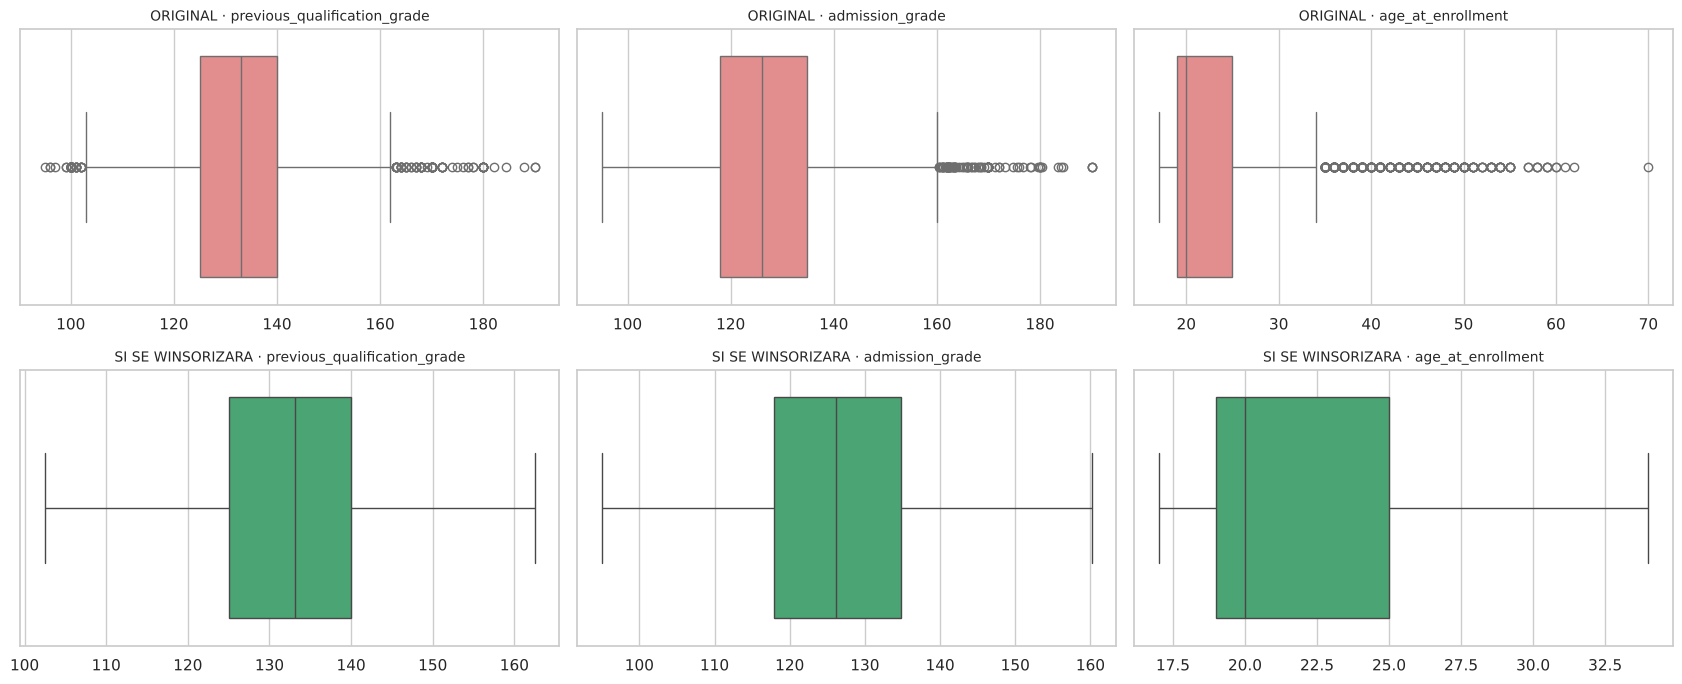

In [32]:
from src.preprocessing import WinsorizadorIQR

K_IQR = 1.5
COLS_WINSOR = ["previous_qualification_grade", "admission_grade", "age_at_enrollment"]

w = WinsorizadorIQR(COLS_WINSOR, k=K_IQR).fit(df_clean)   # solo ilustrativo: en el modelado se ajusta con el train
limites = {c: {"lim_inf": li, "lim_sup": ls,
               "n_afectados": int(((df_clean[c] < li) | (df_clean[c] > ls)).sum())}
           for c, (li, ls) in w.limites_.items()}
display(pd.DataFrame(limites).T)

edad_alta = df_clean["age_at_enrollment"] > w.limites_["age_at_enrollment"][1]
print(f"Estudiantes que se recortarían por edad: {int(edad_alta.sum())} | su tasa de deserción: "
      f"{(df_clean.loc[edad_alta, TARGET] == 'Dropout').mean() * 100:.1f} % (vs. {(df_clean.loc[~edad_alta, TARGET] == 'Dropout').mean() * 100:.1f} % del resto)")

df_wins = w.transform(df_clean)
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for j, c in enumerate(COLS_WINSOR):
    sns.boxplot(x=df_clean[c], ax=axes[0, j], color="lightcoral"); axes[0, j].set_title(f"ORIGINAL · {c}", fontsize=10)
    sns.boxplot(x=df_wins[c], ax=axes[1, j], color="mediumseagreen"); axes[1, j].set_title(f"SI SE WINSORIZARA · {c}", fontsize=10)
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()

bitacora["winsorizacion"] = "no se aplica a los datos; opción evaluada por CV en el pipeline de la Regresión Logística"

## 2.8 Codificación del target 
Scikit-learn trabaja directamente con etiquetas de texto, así que el target se conserva como `Dropout` / `Enrolled` / `Graduate`: las matrices de confusión, los reportes y la aplicación Streamlit muestran los nombres de clase sin tablas de traducción intermedias. El proyecto mantiene la formulación **multiclase**.

In [33]:
MAPA_TARGET = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}   # referencia (orden alfabético que usa scikit-learn)
assert set(df_clean[TARGET].unique()) == set(MAPA_TARGET), "Hay categorías de target no reconocidas"
display(df_clean[TARGET].value_counts().to_frame("estudiantes").assign(
    etiqueta_es=lambda d: d.index.map(dd.CLASS_LABELS_ES)))

,estudiantes,etiqueta_es
target,,
Graduate,2209,Graduado
Dropout,1421,Deserción
Enrolled,794,Matriculado


## 2.9 Validación de calidad (aserciones)

In [ ]:
assert df_clean.isna().sum().sum() == 0, "Persisten nulos"
assert df_clean.drop(columns=["flag_inconsistencia"]).duplicated().sum() == 0, "Persisten duplicados"
assert df_clean["admission_grade"].between(0, 200).all(), "admission_grade fuera de rango"
assert df_clean["previous_qualification_grade"].between(0, 200).all(), "previous_qualification_grade fuera de rango"
assert df_clean["curricular_units_1st_sem_grade"].between(0, 20).all(), "nota 1er sem fuera de rango"
assert df_clean["curricular_units_2nd_sem_grade"].between(0, 20).all(), "nota 2do sem fuera de rango"
assert (df_clean["age_at_enrollment"] >= 14).all(), "edad inválida"
assert set(df_clean[TARGET].unique()) <= set(MAPA_TARGET), "categorías de target inesperadas"

#  Garantía de coherencia: la limpieza de este cuaderno produce EXACTAMENTE el mismo dataset que el pipeline
#    (src/data_loader.clean_dataset), que es el que usan el entrenamiento y Streamlit.
ref = clean_dataset(df_raw)
pd.testing.assert_frame_equal(df_clean.drop(columns=["flag_inconsistencia"]).reset_index(drop=True),
                              ref.reset_index(drop=True), check_dtype=False)
print("✅ Todas las validaciones de calidad pasaron y el dataset coincide con el del pipeline.")

✅ Todas las validaciones de calidad pasaron y el dataset coincide con el del pipeline.


## 2.10 Comparación antes vs. después

In [35]:
comparacion = pd.DataFrame({
    "antes (df)": [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())],
    "después (df_clean)": [len(df_clean), df_clean.shape[1], int(df_clean.isna().sum().sum()), int(df_clean.duplicated().sum())],
}, index=["filas", "columnas", "nulos", "duplicados"])
display(comparacion)

print("\nBitácora de limpieza:")
print(json.dumps(bitacora, indent=2, ensure_ascii=False, default=str))

display(df_clean.head())

,antes (df),después (df_clean)
filas,4424,4424
columnas,37,38
nulos,0,0
duplicados,0,0



Bitácora de limpieza:
{
  "filas_iniciales": 4424,
  "columnas_iniciales": 37,
  "filas_sin_target_eliminadas": 0,
  "duplicados_eliminados": 0,
  "columnas_eliminadas_por_nulos": [],
  "nulos_imputados": {},
  "filas_invalidas_eliminadas": 0,
  "filas_marcadas_sospechosas": 912,
  "winsorizacion": "no se aplica a los datos; opción evaluada por CV en el pipeline de la Regresión Logística"
}


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target,flag_inconsistencia
0,1,17,5,171,1,1,122.000,1,19,12,5,9,127.300,1,0,0,1,1,0,20,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Dropout,1
1,1,15,1,9254,1,1,160.000,1,1,3,3,3,142.500,1,0,0,0,1,0,19,0,0,6,6,6,14.000,0,0,6,6,6,13.667,0,13.900,-0.300,0.790,Graduate,0
2,1,1,5,9070,1,1,122.000,1,37,37,9,9,124.800,1,0,0,0,1,0,19,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Dropout,1
3,1,17,2,9773,1,1,122.000,1,38,37,5,3,119.600,1,0,0,1,0,0,20,0,0,6,8,6,13.429,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduate,0
4,2,39,1,8014,0,1,100.000,1,37,38,9,9,141.500,0,0,0,1,0,0,45,0,0,6,9,5,12.333,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduate,0


In [36]:
# Distribución del target antes vs después (la limpieza no debe sesgar las clases)
cmp = pd.concat([df[TARGET].value_counts(normalize=True).mul(100).rename("antes_%"),
                 df_clean[TARGET].value_counts(normalize=True).mul(100).rename("despues_%")], axis=1)
display(cmp.round(2))

,antes_%,despues_%
target,,
Graduate,49.930,49.930
Dropout,32.120,32.120
Enrolled,17.950,17.950


## 2.11 Exportación del dataset limpio

In [ ]:
#  Se exporta el mismo archivo que usa el pipeline (data/estudiantes_limpio.csv), sin columnas auxiliares.
#    `flag_inconsistencia` es solo de auditoría y se recalcula con src.data_loader.soft_rule_flags.
ruta = save_clean(df_clean.drop(columns=["flag_inconsistencia"]))
print(f"CSV guardado: {ruta.relative_to(ROOT)} ({len(df_clean):,} filas)")

CSV guardado: data/estudiantes_limpio.csv (4,424 filas)


---
## ✅ Resumen de decisiones de limpieza 

| Aspecto | Decisión | Justificación |
|---|---|---|
| Nombres | `snake_case`, corrección `Nacionality → nationality` | Evitar errores por espacios/tab ocultos |
| Duplicados | Eliminar exactos | Evitan sobre-representar casos (había 0) |
| Nulos | Mediana (num) / moda (cat); columna > 40 % se elimina | Robusto a sesgo; el dataset original no tiene nulos |
| Tipos | Enteros para códigos y conteos | Tipos coherentes |
| Consistencia | Duras → eliminar; blandas → `flag_inconsistencia` | No perder desertores reales con 0 materias |
| Outliers |  Se conservan; winsorización IQR como opción validada por CV en la Logística | Son casos legítimos; recortar la edad borra información del grupo de mayor riesgo |
| Target |  Texto (`Dropout`/`Enrolled`/`Graduate`), multiclase | Scikit-learn lo maneja directamente |


---
# 🧪 PARTE 3 — Preparación del dataset para modelado
Aquí dejamos todo listo para entrenar: partición **estratificada** por clase, validación cruzada y *pipelines* de preprocesamiento que aprenden **solo del entrenamiento** (sin fuga de datos).

### Modelos previstos y por qué (justificación completa en la sección 4.0)
| Modelo | Preprocesamiento | Qué aporta al análisis |
|---|---|---|
| **Regresión Logística** (regularizada) | escalado + one-hot (+ winsorización opcional) | Referencia; coeficientes interpretables |
| **Random Forest** | sin escalado,  categóricas en one-hot | Robusto y estable; importancia de variables |
| **Gradient Boosting** (`HistGradientBoosting`) | sin escalado, categóricas **nativas** | Mejor rendimiento esperado |

**Métricas comunes:** accuracy, macro-F1, balanced accuracy, F1 por clase y matriz de confusión, con validación cruzada de 5 folds (la desviación entre folds indica qué tan estable es la conclusión).

## 3.1 Dataset de modelado: variables (X) y objetivo (y)

In [ ]:
#  Conjuntos de variables definidos en src/preprocessing.py (FULL = todas, EARLY = sin 2.º semestre)
from src.preprocessing import FULL, EARLY
from src.train import split_data, make_cv, TEST_SIZE, CV_FOLDS

N_FOLDS = CV_FOLDS
df_model = df_clean.drop(columns=["flag_inconsistencia"])   # USAR_FLAG_INCONSISTENCIA = False
features = FULL.raw_columns
bin_cols, cat_cols, num_cols = list(FULL.binary), list(FULL.nominal), list(FULL.numeric)
assert set(bin_cols + cat_cols + num_cols) == set(features), "Hay columnas sin clasificar"

X = df_model[features]
y = df_model[TARGET]
ETIQUETAS = dd.CLASS_LABELS_ES   # Dropout -> Deserción, Enrolled -> Matriculado, Graduate -> Graduado

print(f"X: {X.shape} | y: {y.shape} | objetivo = '{TARGET}' (3 clases)")
print(f"Numéricas: {len(num_cols)} | Binarias: {len(bin_cols)} | Categóricas codificadas: {len(cat_cols)}")

X: (4424, 36) | y: (4424,) | objetivo = 'target' (3 clases)
Numéricas: 19 | Binarias: 8 | Categóricas codificadas: 9


## 3.2 Partición estratificada (porcentajes por categoría)
`stratify=y` hace que **cada subconjunto conserve el mismo porcentaje de cada clase** que el dataset completo. Es clave aquí porque `Enrolled` es solo ~18 %.
Se usa **80 % entrenamiento / 20 % prueba**; el conjunto de prueba no se toca hasta la evaluación final.

,total_%,train_%,test_%,n_total,n_train,n_test
Deserción,32.120,32.130,32.090,1421,1137,284
Matriculado,17.950,17.940,17.970,794,635,159
Graduado,49.930,49.930,49.940,2209,1767,442


Train: 3,539 filas (80%) | Test: 885 filas (20%)


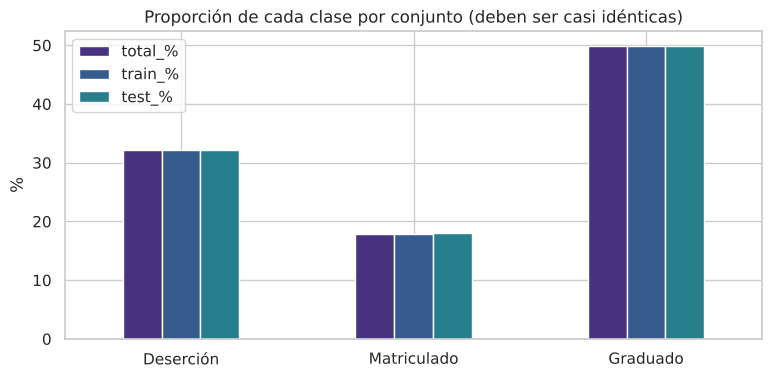

In [ ]:
#  misma partición que el entrenamiento oficial (src/train.split_data: test_size=0.20, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = split_data(df_model, FULL)

tabla_split = pd.DataFrame({
    "total_%": y.value_counts(normalize=True).sort_index() * 100,
    "train_%": y_train.value_counts(normalize=True).sort_index() * 100,
    "test_%": y_test.value_counts(normalize=True).sort_index() * 100,
    "n_total": y.value_counts().sort_index(),
    "n_train": y_train.value_counts().sort_index(),
    "n_test": y_test.value_counts().sort_index(),
})
tabla_split.index = [ETIQUETAS[i] for i in tabla_split.index]
display(tabla_split.round(2))
print(f"Train: {len(X_train):,} filas ({len(X_train) / len(X) * 100:.0f}%) | Test: {len(X_test):,} filas ({len(X_test) / len(X) * 100:.0f}%)")

tabla_split[["total_%", "train_%", "test_%"]].plot.bar(rot=0, figsize=(9, 4))
plt.title("Proporción de cada clase por conjunto (deben ser casi idénticas)"); plt.ylabel("%"); plt.show()

## 3.3 Validación cruzada estratificada
Dentro del entrenamiento se usan **5 folds estratificados**: cada modelo se evalúa 5 veces y se reporta media ± desviación. Así la conclusión no depende de una sola partición.

In [ ]:
cv = make_cv()   #  StratifiedKFold(n_splits=5, shuffle=True, random_state=42), igual que src/train.py

filas = []
for k, (idx_tr, idx_va) in enumerate(cv.split(X_train, y_train), start=1):
    prop = y_train.iloc[idx_va].value_counts(normalize=True).sort_index() * 100
    filas.append({"fold": k, "n_validacion": len(idx_va), **{ETIQUETAS[i]: round(v, 1) for i, v in prop.items()}})
display(pd.DataFrame(filas).set_index("fold"))

,n_validacion,Deserción,Matriculado,Graduado
fold,,,,
1,708,32.100,17.900,50.000
2,708,32.100,17.900,50.000
3,708,32.200,17.900,49.900
4,708,32.200,17.900,49.900
5,707,32.100,18.000,49.900


## 3.4 Desbalance de clases: pesos
En lugar de inventar datos (SMOTE), se usará `class_weight="balanced"`: penaliza más los errores en las clases minoritarias. Estos son los pesos que se aplicarían.

>  En la versión refactorizada `class_weight` es un **hiperparámetro** de la rejilla (`None` vs. balanceado) y la validación cruzada decide; así el tratamiento del desbalance queda justificado con evidencia.

In [41]:
from sklearn.utils.class_weight import compute_class_weight

clases = np.sort(y_train.unique())
pesos = compute_class_weight("balanced", classes=clases, y=y_train)
display(pd.DataFrame({"clase": [ETIQUETAS[c] for c in clases], "peso": pesos.round(3)}).set_index("clase"))

,peso
clase,
Deserción,1.038
Matriculado,1.858
Graduado,0.668


## 3.5 Pipelines de preprocesamiento (sin fuga de datos) 
Todo lo que se "aprende" de los datos (límites IQR, media/desviación del escalado, categorías del one-hot) se ajusta **solo con el entrenamiento** y luego se aplica al test. 
1. `features` — `AcademicFeatureEngineer`: añade la **tasa de aprobación por semestre** (aprobadas / inscritas; 0 si no inscribió). Es una operación fila a fila, sin parámetros aprendidos.
2. `winsor` — `WinsorizadorIQR`; `passthrough` por defecto y opción de la rejilla en la Logística.
3. `prep` — `ColumnTransformer` específico por modelo:
   - **Logística**: numéricas con `StandardScaler` + categóricas en one-hot (categorías con < 10 casos se agrupan como «infrecuentes»).
   - **Random Forest**: numéricas sin escalar +  categóricas en one-hot (el `OrdinalEncoder` imponía un orden arbitrario a los códigos).
   - **Gradient Boosting**: numéricas sin escalar + categóricas ordinales declaradas como **categóricas nativas** (`categorical_features`) .
4. `clf` — el clasificador.


In [42]:
from src.train import build_estimator

pipes = {k: build_estimator(k, FULL)[0] for k in ["logreg", "rf", "hgb"]}
for k, p in pipes.items():
    print(f"--- {k} ---"); print(p, "\n")

--- logreg ---
Pipeline(steps=[('features', AcademicFeatureEngineer()),
                ('winsor', 'passthrough'),
                ('prep',
                 ColumnTransformer(transformers=[('nominal',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10,
                                                                sparse_output=False),
                                                  ['marital_status',
                                                   'application_mode', 'course',
                                                   'previous_qualification',
                                                   'nationality',
                                                   'mothers_qualification',
                                                   'fathers_qualificatio...
                                                   'curricular_units_2nd_sem_evaluat

## 3.6 Verificación: el preprocesamiento funciona y no hay fuga

In [43]:
prep_lineal = pipes["logreg"][:-1].set_params(winsor=WinsorizadorIQR(COLS_WINSOR, k=K_IQR))   # pasos sin el clasificador
prep_arboles = pipes["hgb"][:-1]

Xtr_lin = prep_lineal.fit_transform(X_train)     # se ajusta SOLO con el train
Xte_lin = prep_lineal.transform(X_test)           # el test solo se transforma
Xtr_arb = prep_arboles.fit_transform(X_train)
Xte_arb = prep_arboles.transform(X_test)

print(f"Lineal  -> train {Xtr_lin.shape} | test {Xte_lin.shape}  (one-hot expande {len(cat_cols)} categóricas)")
print(f"Árboles -> train {Xtr_arb.shape} | test {Xte_arb.shape}  (categóricas nativas: 1 columna por variable)")
assert not np.isnan(Xtr_lin).any() and not np.isnan(Xte_lin).any(), "Hay NaN tras transformar"
assert Xtr_lin.shape[1] == Xte_lin.shape[1] and Xtr_arb.shape[1] == Xte_arb.shape[1]

# Las numéricas escaladas deben tener media ~0 y std ~1 en el TRAIN (y aproximada en el test)
nombres_lin = list(prep_lineal[-1].get_feature_names_out())
idx_num = [nombres_lin.index(c) for c in FULL.numeric_with_engineered]
print(f"\nNuméricas escaladas | train: media={Xtr_lin[:, idx_num].mean():.3f}, std={Xtr_lin[:, idx_num].std():.3f} "
      f"| test: media={Xte_lin[:, idx_num].mean():.3f}, std={Xte_lin[:, idx_num].std():.3f}")

# Límites de winsorización aprendidos solo con el train
lim = pd.DataFrame(prep_lineal.named_steps["winsor"].limites_, index=["lim_inf", "lim_sup"]).T
display(lim.round(2))

Lineal  -> train (3539, 134) | test (885, 134)  (one-hot expande 9 categóricas)
Árboles -> train (3539, 38) | test (885, 38)  (categóricas nativas: 1 columna por variable)

Numéricas escaladas | train: media=-0.000, std=1.000 | test: media=0.008, std=1.011


,lim_inf,lim_sup
previous_qualification_grade,102.500,162.500
admission_grade,92.150,160.550
age_at_enrollment,10.000,34.000


## 3.7 Conjuntos para el modelado 
La partición se reproduce exactamente con `split_data` (semilla 42) y los metadatos completos (columnas, categorías, partición, versiones) se guardan junto al modelo en `models/metadata.json`.

### ✅ Resumen de la preparación
| Decisión | Valor | Justificación |
|---|---|---|
| Partición | 80 % train / 20 % test, **estratificada** | Mantiene el % de cada clase (incluida `Enrolled`) |
| Validación | StratifiedKFold de 5 folds | Conclusiones estables (media ± desviación) |
| Desbalance |  `class_weight` como hiperparámetro (`None` vs. balanceado) | Sin inventar datos sintéticos; decisión validada por CV |
| Fuga de datos | Winsorización, escalado y one-hot dentro del `Pipeline` | El test nunca influye en el preprocesamiento |
| Modelos | Logística, Random Forest, Gradient Boosting | Interpretables, estables y comparables |

---
# 🤖 PARTE 4 — Modelado clásico y evaluación
Se entrenan y comparan **3 modelos** con el mismo protocolo, para que la comparación sea justa:

1. **Regresión Logística** regularizada (referencia, interpretable)
2. **Random Forest** (robusto y estable)
3. **Gradient Boosting** (`HistGradientBoosting`, mejor rendimiento esperado)

**Protocolo:**
`CV base (5 folds)` → `ajuste de hiperparámetros con GridSearchCV (métrica macro-F1)` →  `selección del modelo por CV` → `evaluación final única sobre el test` → `interpretación` → `exportación para Streamlit`.

> **Métrica principal: macro-F1.** Promedia el F1 de las 3 clases con el mismo peso, así que no se deja engañar por la clase mayoritaria (`Graduate`, ~50 %). Se acompaña de balanced accuracy y accuracy.

## 4.0 ¿Por qué estos tres modelos?
La elección no es arbitraria: sale de lo que mostró el EDA y de comparar **tres familias de algoritmos distintas** (lineal, *bagging* y *boosting*). Si familias tan diferentes llegan a un rendimiento parecido, la conclusión es **estable** y no depende de un algoritmo particular.

| | **Regresión Logística** (regularizada) | **Random Forest** | **Gradient Boosting** |
|---|---|---|---|
| **Familia** | Lineal / probabilística | Ensamble *bagging*: muchos árboles independientes que votan | Ensamble *boosting*: árboles en secuencia, cada uno corrige los errores del anterior |
| **Caso de uso típico** | Clasificación y *scoring* de riesgo donde se necesita explicar la decisión (crédito, diagnóstico) | Clasificación sobre tablas con variables de distinto tipo (fuga de clientes, fraude) | Predicción sobre datos tabulares cuando se busca la máxima precisión (riesgo, deserción, *churn*) |
| **Fortaleza** | Interpretable (cada coeficiente indica el efecto de la variable), rápida y poco propensa al sobreajuste | Capta relaciones no lineales e interacciones, no necesita escalar y es robusta a outliers | Suele ser el más preciso en datos tabulares; admite pesos por clase |
| **Limitación** | Supone fronteras lineales; exige escalado y one-hot; no capta interacciones por sí sola | Menos interpretable; tiende a memorizar el entrenamiento (sobreajuste) | Más hiperparámetros que ajustar; riesgo de sobreajuste; menos interpretable |
| **Por qué encaja aquí** | El EDA mostró **multicolinealidad** fuerte (11 pares con \|r\| ≥ 0,7; máx. 0,945 entre semestres): la regularización L2 la controla. Sirve de **referencia** y explica *qué* variables elevan la deserción | **16 de 19** numéricas tienen outliers y 9 están muy sesgadas: los árboles no se ven afectados por la escala ni por valores extremos. Maneja la mezcla de numéricas, binarias y categóricas codificadas | Es el candidato natural a mejor rendimiento y a **modelo final**; 4.424 registros son suficientes para entrenarlo sin problema |
| **Preprocesamiento** | Escalado + one-hot (+ winsorización opcional) | Sin escalado;  categóricas en one-hot | Sin escalado;  categóricas nativas |

**Modelos considerados y descartados**
- **Regresión lineal:** es para predecir valores continuos; aquí el objetivo es una clase.
- **Árbol de decisión simple:** es inestable y sobreajusta; el Random Forest lo mejora y lo incluye.
- **KNN:** sufre con muchas variables mezcladas y correlacionadas (≈ 247 columnas tras un one-hot sin agrupar) y es lento al predecir.
- **SVM (kernel RBF):** posible, pero más costoso, exige ajustar `C` y `gamma`, y es poco interpretable; no aporta una familia nueva frente a los tres elegidos.

**Criterio de comparación:** los tres se evalúan con el mismo protocolo (mismas particiones, mismas métricas y macro-F1 como métrica principal), de modo que cualquier diferencia se deba al modelo y no al procedimiento.

## 4.1 Definición de los modelos

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
from src.train import fit_modality, export_modality

SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "f1_macro": "f1_macro"}
ES_MULTICLASE = y.nunique() > 2
CLASES = sorted(y.unique())
NOMBRES_CLASES = [ETIQUETAS[c] for c in CLASES]
NOMBRE = {"logreg": "Regresión Logística", "rf": "Random Forest", "hgb": "Gradient Boosting"}

modelos_base = {NOMBRE[k]: build_estimator(k, FULL, default_class_weight="balanced")[0] for k in NOMBRE}
print("Modelos definidos:", list(modelos_base))

Modelos definidos: ['Regresión Logística', 'Random Forest', 'Gradient Boosting']


## 4.2 Validación cruzada base (hiperparámetros por defecto)
Cada modelo se evalúa en los mismos 5 folds estratificados. Se reporta **media ± desviación**: una desviación pequeña indica un resultado **estable**.
La *brecha train–val* en macro-F1 mide el sobreajuste (mucho más alto en train que en validación = memoriza).

In [45]:
def resumen_cv(resultados):
    filas = {}
    for nombre, r in resultados.items():
        filas[nombre] = {
            "accuracy": r["test_accuracy"].mean(), "accuracy_std": r["test_accuracy"].std(),
            "bal_accuracy": r["test_balanced_accuracy"].mean(), "bal_accuracy_std": r["test_balanced_accuracy"].std(),
            "f1_macro": r["test_f1_macro"].mean(), "f1_macro_std": r["test_f1_macro"].std(),
            "f1_macro_train": r["train_f1_macro"].mean(),
        }
    d = pd.DataFrame(filas).T
    d["brecha_train_val"] = d["f1_macro_train"] - d["f1_macro"]
    return d


resultados_base = {n: cross_validate(m, X_train, y_train, cv=cv, scoring=SCORING,
                                     return_train_score=True, n_jobs=-1)
                   for n, m in modelos_base.items()}
tabla_cv_base = resumen_cv(resultados_base)
display(tabla_cv_base.round(3))

,accuracy,accuracy_std,bal_accuracy,bal_accuracy_std,f1_macro,f1_macro_std,f1_macro_train,brecha_train_val
Regresión Logística,0.754,0.013,0.721,0.015,0.713,0.014,0.762,0.050
Random Forest,0.778,0.012,0.688,0.019,0.698,0.021,1.000,0.302
Gradient Boosting,0.776,0.008,0.711,0.015,0.716,0.014,1.000,0.284


## 4.3 Ajuste de hiperparámetros (GridSearchCV) 

| Modelo | Rejilla |
|---|---|
| Regresión Logística | `C` ∈ {0,01; 0,03; 0,1; 0,3; 1; 3} × `class_weight` ∈ {None, balanced} × `winsor` ∈ {passthrough, WinsorizadorIQR} |
| Random Forest (300 árboles) | `max_depth` ∈ {8, 12, None} × `min_samples_leaf` ∈ {1, 3, 5} × `max_features` ∈ {sqrt, 0,5} × `class_weight` ∈ {None, balanced_subsample} |
| Gradient Boosting | `learning_rate` ∈ {0,03; 0,1} × `max_depth` ∈ {3, 6} × `min_samples_leaf` ∈ {20, 40} × `max_iter` ∈ {150, 300} × `class_weight` ∈ {None, balanced} |

La búsqueda la ejecuta `src.train.fit_modality`, **la misma función** que usa `python -m src.train`, para que los resultados de este cuaderno y los artefactos de Streamlit sean idénticos. Tarda unos minutos.

In [46]:
res_full = fit_modality(df_model, FULL)
assert res_full.X_train.index.equals(X_train.index), "La partición debe coincidir con la de la Parte 3"

mejores = {NOMBRE[k]: s for k, s in res_full.searches.items()}
for nombre, gs in mejores.items():
    print(f"{nombre:<22} mejor macro-F1 (CV) = {gs.best_score_:.3f} | {gs.best_params_}")

Regresión Logística    mejor macro-F1 (CV) = 0.717 | {'clf__C': 0.3, 'clf__class_weight': 'balanced', 'winsor': 'passthrough'}
Random Forest          mejor macro-F1 (CV) = 0.724 | {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3}
Gradient Boosting      mejor macro-F1 (CV) = 0.730 | {'clf__class_weight': 'balanced', 'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__max_iter': 300, 'clf__min_samples_leaf': 20}


## 4.4 CV de los modelos ajustados vs. base

,accuracy,accuracy_std,bal_accuracy,bal_accuracy_std,f1_macro,f1_macro_std,f1_macro_train,brecha_train_val
Regresión Logística,0.758,0.015,0.725,0.019,0.717,0.017,0.759,0.042
Random Forest,0.775,0.014,0.722,0.017,0.724,0.017,0.916,0.191
Gradient Boosting,0.771,0.010,0.736,0.008,0.730,0.009,0.862,0.132


,f1_macro base,f1_macro ajustado,mejora
Regresión Logística,0.713,0.717,0.005
Random Forest,0.698,0.724,0.027
Gradient Boosting,0.716,0.730,0.014


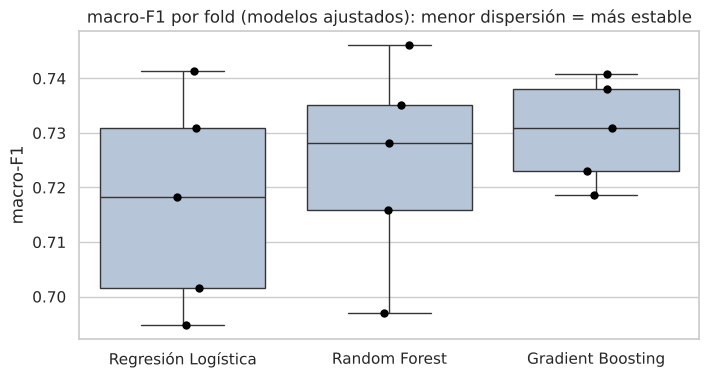

In [ ]:
#  Las métricas de CV del mejor modelo se toman de la propia búsqueda (no hace falta repetir cross_validate)
tabla_cv_aj = pd.DataFrame({
    NOMBRE[k]: {
        "accuracy": r["cv"]["accuracy"]["media"], "accuracy_std": r["cv"]["accuracy"]["desv"],
        "bal_accuracy": r["cv"]["balanced_accuracy"]["media"], "bal_accuracy_std": r["cv"]["balanced_accuracy"]["desv"],
        "f1_macro": r["cv"]["f1_macro"]["media"], "f1_macro_std": r["cv"]["f1_macro"]["desv"],
        "f1_macro_train": r["cv"]["f1_macro"]["media_train"],
    } for k, r in res_full.results.items()}).T
tabla_cv_aj["brecha_train_val"] = tabla_cv_aj["f1_macro_train"] - tabla_cv_aj["f1_macro"]
display(tabla_cv_aj.round(3))

mejora = pd.DataFrame({"f1_macro base": tabla_cv_base["f1_macro"], "f1_macro ajustado": tabla_cv_aj["f1_macro"]})
mejora["mejora"] = mejora["f1_macro ajustado"] - mejora["f1_macro base"]
display(mejora.round(3))

# Estabilidad: distribución del macro-F1 en cada fold
folds = pd.DataFrame({NOMBRE[k]: r["cv"]["f1_macro"]["pliegues"] for k, r in res_full.results.items()})
plt.figure(figsize=(8, 4))
sns.boxplot(data=folds, color="lightsteelblue")
sns.stripplot(data=folds, color="black", size=6)
plt.title("macro-F1 por fold (modelos ajustados): menor dispersión = más estable"); plt.ylabel("macro-F1")
plt.show()

## 4.5 Selección del modelo (por CV) y evaluación final sobre el TEST 
El modelo se elige con el **macro-F1 medio de validación cruzada** y, después, el 20 % reservado se usa una sola vez para estimar el desempeño en estudiantes nuevos.
Se agrega **ROC-AUC** (un-vs-resto, promedio macro), que mide qué tan bien separa cada modelo las clases sin depender de un umbral.

In [48]:
ranking_cv = tabla_cv_aj["f1_macro"].sort_values(ascending=False)
mejor = ranking_cv.index[0]
assert mejor == NOMBRE[res_full.winner]
print("Ranking por macro-F1 en validación cruzada (criterio de selección):")
display(ranking_cv.round(4).to_frame("macro-F1 CV"))
print(f"→ Modelo seleccionado ANTES de mirar el test: {mejor}")

Ranking por macro-F1 en validación cruzada (criterio de selección):


,macro-F1 CV
Gradient Boosting,0.730
Random Forest,0.724
Regresión Logística,0.717


→ Modelo seleccionado ANTES de mirar el test: Gradient Boosting


,accuracy,balanced_accuracy,f1_macro,f1_weighted,roc_auc_ovr
Random Forest,0.769,0.716,0.717,0.770,0.890
Gradient Boosting,0.729,0.697,0.688,0.740,0.881
Regresión Logística,0.724,0.695,0.684,0.737,0.883


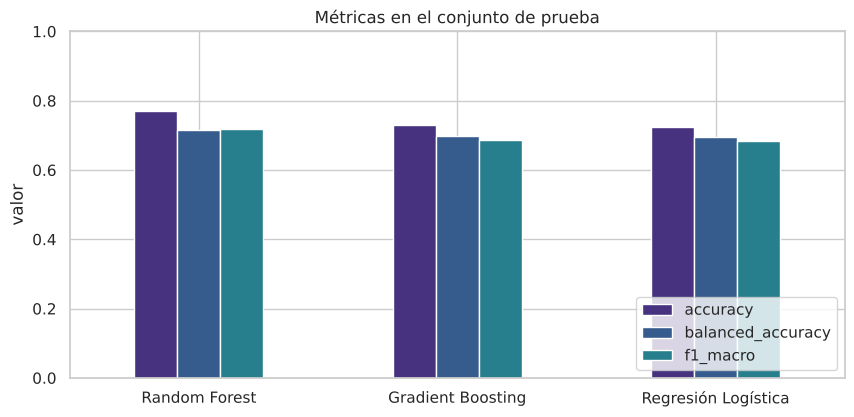

In [49]:
def evaluar(modelo, Xt, yt):
    pred = modelo.predict(Xt)
    proba = modelo.predict_proba(Xt)
    auc = roc_auc_score(yt, proba, multi_class="ovr", average="macro", labels=modelo.classes_) if ES_MULTICLASE else roc_auc_score(yt, proba[:, 1])
    return pred, {"accuracy": accuracy_score(yt, pred),
                  "balanced_accuracy": balanced_accuracy_score(yt, pred),
                  "f1_macro": f1_score(yt, pred, average="macro"),
                  "f1_weighted": f1_score(yt, pred, average="weighted"),
                  "roc_auc_ovr": auc}


predicciones, metricas_test = {}, {}
for nombre, gs in mejores.items():
    predicciones[nombre], metricas_test[nombre] = evaluar(gs.best_estimator_, X_test, y_test)

tabla_test = pd.DataFrame(metricas_test).T.sort_values("f1_macro", ascending=False)
display(tabla_test.round(3))

tabla_test[["accuracy", "balanced_accuracy", "f1_macro"]].plot.bar(rot=0, figsize=(10, 4.5), ylim=(0, 1))
plt.title("Métricas en el conjunto de prueba"); plt.ylabel("valor"); plt.legend(loc="lower right")
plt.show()

## 4.6 Desempeño por clase y matrices de confusión
La matriz está **normalizada por fila** (cada fila suma 100 %): la diagonal es el *recall* de cada clase, es decir, qué porcentaje de los estudiantes reales de esa clase detecta el modelo.

,Regresión Logística,Random Forest,Gradient Boosting
Deserción,0.738,0.772,0.749
Matriculado,0.489,0.520,0.490
Graduado,0.825,0.859,0.825



=== Regresión Logística ===


,precision,recall,f1-score,support
Deserción,0.794,0.690,0.738,284.000
Matriculado,0.410,0.604,0.489,159.000
Graduado,0.864,0.790,0.825,442.000
accuracy,0.724,0.724,0.724,0.724
macro avg,0.689,0.695,0.684,885.000
weighted avg,0.760,0.724,0.737,885.000



=== Random Forest ===


,precision,recall,f1-score,support
Deserción,0.821,0.729,0.772,284.000
Matriculado,0.500,0.541,0.520,159.000
Graduado,0.842,0.878,0.859,442.000
accuracy,0.769,0.769,0.769,0.769
macro avg,0.721,0.716,0.717,885.000
weighted avg,0.774,0.769,0.770,885.000



=== Gradient Boosting ===


,precision,recall,f1-score,support
Deserción,0.808,0.697,0.749,284.000
Matriculado,0.415,0.597,0.490,159.000
Graduado,0.856,0.796,0.825,442.000
accuracy,0.729,0.729,0.729,0.729
macro avg,0.693,0.697,0.688,885.000
weighted avg,0.762,0.729,0.740,885.000


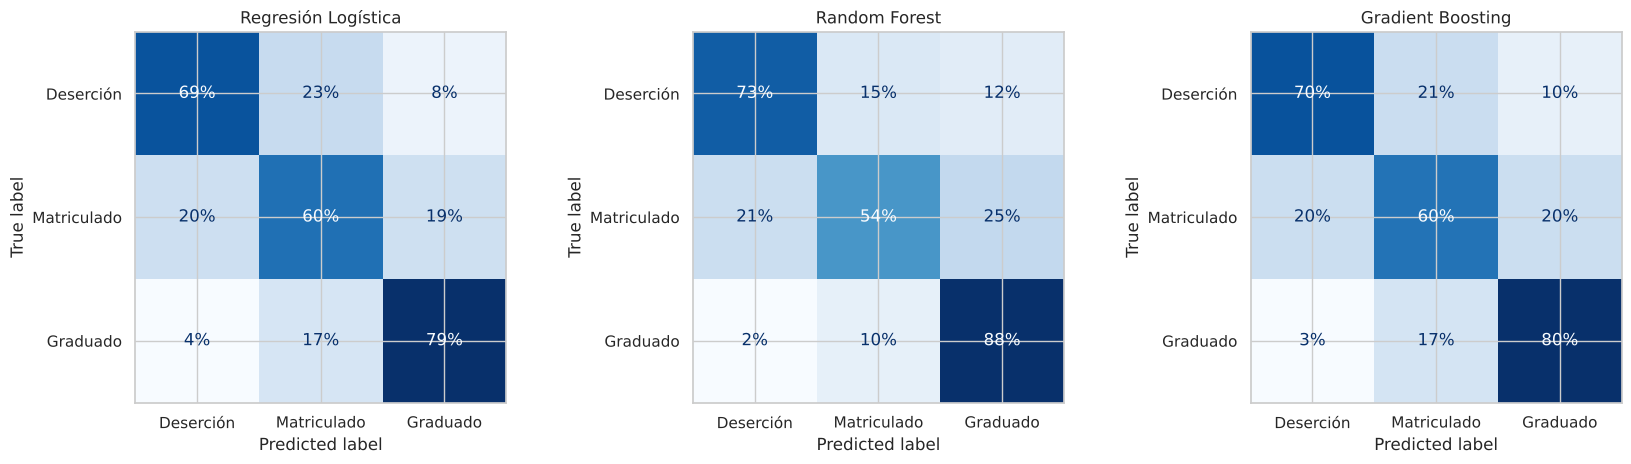

In [50]:
# F1 por clase
f1_clase = pd.DataFrame({n: f1_score(y_test, p, average=None, labels=CLASES) for n, p in predicciones.items()},
                        index=NOMBRES_CLASES)
display(f1_clase.round(3))

# Reporte completo (precision / recall / f1) por modelo
for n, p in predicciones.items():
    rep = pd.DataFrame(classification_report(y_test, p, target_names=NOMBRES_CLASES, output_dict=True)).T
    print(f"\n=== {n} ===")
    display(rep.round(3))

# Matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (n, p) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=NOMBRES_CLASES, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()

## 4.7 Sobreajuste y consistencia CV ↔ Test

In [51]:
consistencia = pd.DataFrame({
    "f1_macro train (CV)": tabla_cv_aj["f1_macro_train"],
    "f1_macro validación (CV)": tabla_cv_aj["f1_macro"],
    "f1_macro test": tabla_test["f1_macro"],
}).loc[list(mejores)]
consistencia["brecha train-val"] = consistencia["f1_macro train (CV)"] - consistencia["f1_macro validación (CV)"]
consistencia["diferencia val-test"] = consistencia["f1_macro validación (CV)"] - consistencia["f1_macro test"]
display(consistencia.round(3))
print("Lectura: brecha train-val alta = sobreajuste; diferencia val-test cercana a 0 = el resultado es confiable.")

,f1_macro train (CV),f1_macro validación (CV),f1_macro test,brecha train-val,diferencia val-test
Regresión Logística,0.759,0.717,0.684,0.042,0.033
Random Forest,0.916,0.724,0.717,0.191,0.007
Gradient Boosting,0.862,0.730,0.688,0.132,0.042


Lectura: brecha train-val alta = sobreajuste; diferencia val-test cercana a 0 = el resultado es confiable.


## 4.8 Interpretación: ¿qué variables explican la deserción?
- **Regresión Logística:** coeficientes estandarizados hacia la clase `Dropout` (positivo = aumenta la probabilidad de desertar).
- **Random Forest y Gradient Boosting:** *importancia por permutación* en el test (cuánto cae el macro-F1 al desordenar una variable). Funciona igual en cualquier modelo y evita los sesgos de la importancia por impuridad.

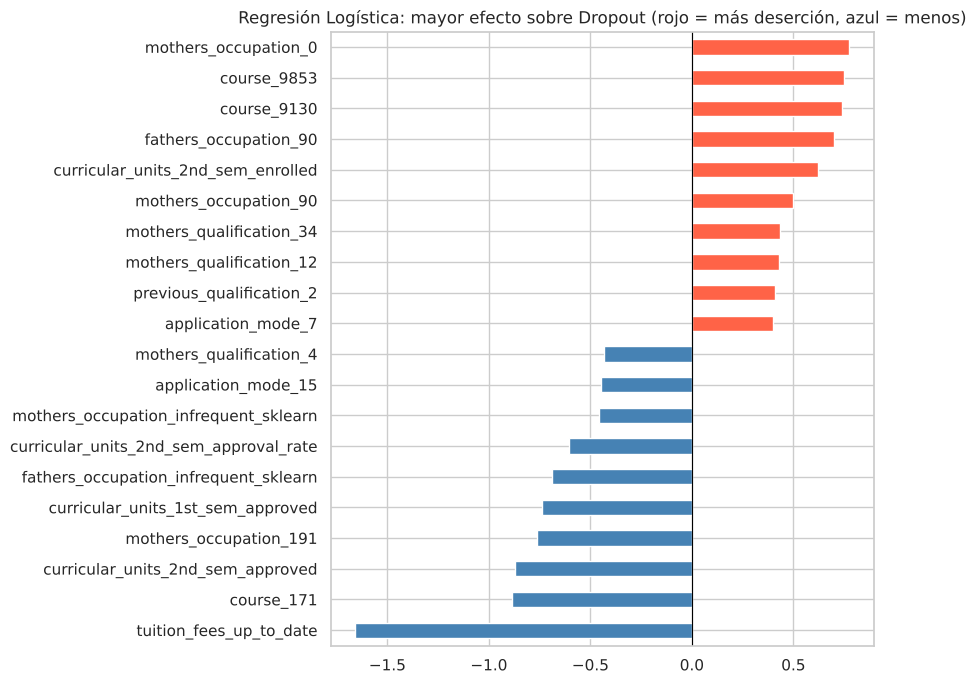

In [ ]:
# --- Coeficientes de la Logística hacia la clase Dropout ---
lr = mejores["Regresión Logística"].best_estimator_
nombres = list(lr.named_steps["prep"].get_feature_names_out())    #  nombres sin prefijo del ColumnTransformer
fila = list(lr.named_steps["clf"].classes_).index("Dropout")
coef = pd.Series(lr.named_steps["clf"].coef_[fila], index=nombres).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])

plt.figure(figsize=(9, 7))
top.plot.barh(color=np.where(top > 0, "tomato", "steelblue"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Regresión Logística: mayor efecto sobre Dropout (rojo = más deserción, azul = menos)")
plt.tight_layout(); plt.show()

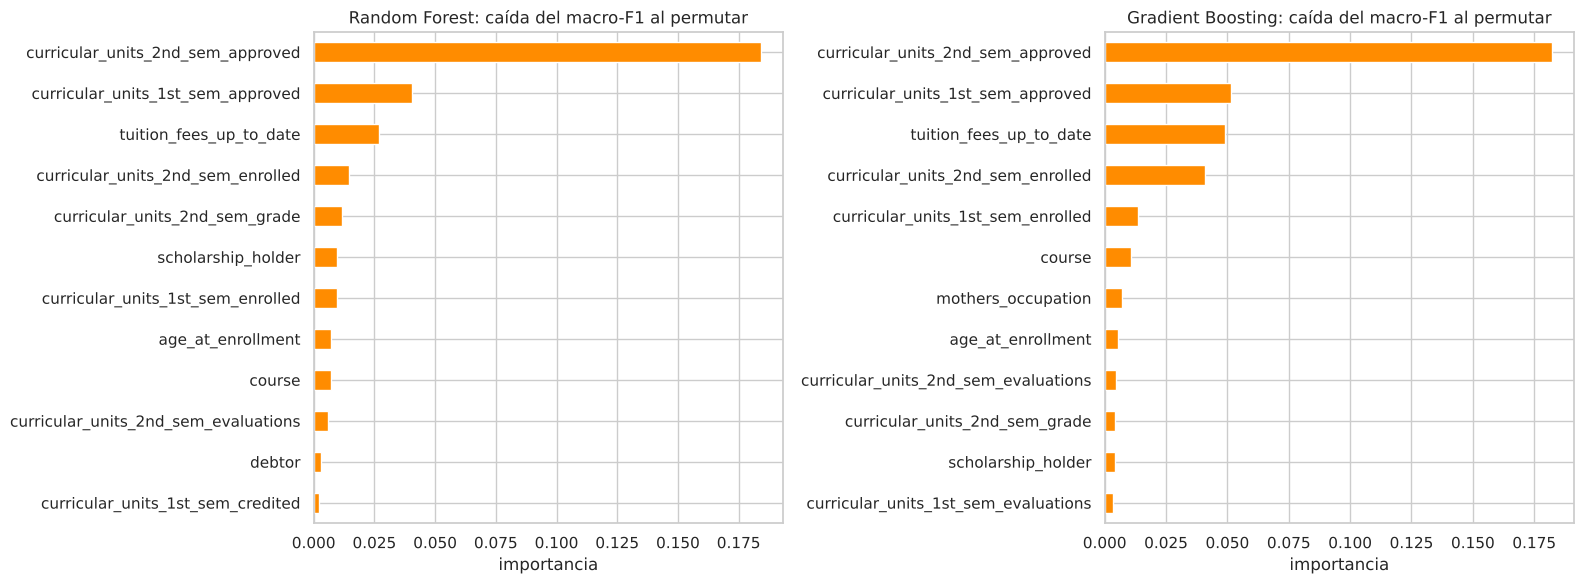

Variables más importantes en común (ranking promedio RF + Boosting):


,ranking_promedio
curricular_units_2nd_sem_approved,1.000
curricular_units_1st_sem_approved,2.000
tuition_fees_up_to_date,3.000
curricular_units_2nd_sem_enrolled,4.000
curricular_units_1st_sem_enrolled,6.000
course,7.500
curricular_units_2nd_sem_grade,7.500
age_at_enrollment,8.000


In [53]:
# --- Importancia por permutación (RF y Gradient Boosting) ---
imp = {}
for n in ["Random Forest", "Gradient Boosting"]:
    r = permutation_importance(mejores[n].best_estimator_, X_test, y_test, scoring="f1_macro",
                               n_repeats=8, random_state=SEED, n_jobs=-1)
    imp[n] = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (n, s) in zip(axes, imp.items()):
    s.head(12).sort_values().plot.barh(ax=ax, color="darkorange")
    ax.set_title(f"{n}: caída del macro-F1 al permutar"); ax.set_xlabel("importancia")
plt.tight_layout(); plt.show()

top_comun = pd.DataFrame({n: s.rank(ascending=False) for n, s in imp.items()}).mean(axis=1).sort_values().head(8)
print("Variables más importantes en común (ranking promedio RF + Boosting):")
display(top_comun.to_frame("ranking_promedio").round(1))

## 4.9 Experimento adicional: ¿se puede avisar a tiempo? (alerta temprana) 
Las variables del **2.º semestre** son muy informativas, pero llegan tarde: cuando se conocen, muchos estudiantes ya desertaron.

La alerta temprana es un **modelo independiente**: se repite todo el protocolo (los tres algoritmos, GridSearchCV y selección por CV) con un conjunto de variables que excluye las 6 del 2.º semestre (`EARLY`), y se exporta con su propio artefacto (`models/modelo_temprano.joblib`).

> La tabla de abajo cuantifica **cuánto se pierde por usar menos información**. No compara dos modelos sobre el mismo problema: cada uno responde a un momento distinto de la trayectoria del estudiante.

In [54]:
res_early = fit_modality(df_model, EARLY)
cols_2do = sorted(set(FULL.raw_columns) - set(EARLY.raw_columns))
print(f"Variables del 2.º semestre excluidas ({len(cols_2do)}): {cols_2do}")

display(pd.DataFrame({NOMBRE[k]: {"f1_macro CV": r["cv"]["f1_macro"]["media"], "f1_macro test": r["prueba"]["f1_macro"],
                                  "bal_acc test": r["prueba"]["balanced_accuracy"], "accuracy test": r["prueba"]["accuracy"]}
                      for k, r in res_early.results.items()}).T.round(3))
print(f"→ Modelo de alerta temprana seleccionado por CV: {NOMBRE[res_early.winner]} | {res_early.results[res_early.winner]['mejores_hiperparametros']}")

comp = pd.DataFrame({
    f"{NOMBRE[res_full.winner]} · información completa": res_full.results[res_full.winner]["prueba"],
    f"{NOMBRE[res_early.winner]} · solo hasta 1.er semestre": res_early.results[res_early.winner]["prueba"],
}).T[["accuracy", "balanced_accuracy", "f1_macro", "roc_auc_ovr_macro"]]
comp["f1_macro: pérdida por anticipar"] = comp["f1_macro"].iloc[0] - comp["f1_macro"]
display(comp.astype(float).round(3))

Variables del 2.º semestre excluidas (6): ['curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations']


,f1_macro CV,f1_macro test,bal_acc test,accuracy test
Regresión Logística,0.688,0.666,0.676,0.704
Random Forest,0.694,0.685,0.688,0.737
Gradient Boosting,0.699,0.669,0.677,0.711


→ Modelo de alerta temprana seleccionado por CV: Gradient Boosting | {'class_weight': 'balanced', 'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 300, 'min_samples_leaf': 20}


,accuracy,balanced_accuracy,f1_macro,roc_auc_ovr_macro,f1_macro: pérdida por anticipar
Gradient Boosting · información completa,0.729,0.697,0.688,0.881,0.000
Gradient Boosting · solo hasta 1.er semestre,0.711,0.677,0.669,0.862,0.019


## 4.10 Ranking final automático 
El orden y el modelo recomendado salen de la **validación cruzada**; las métricas de test se muestran como estimación final.

In [55]:
orden = tabla_test.loc[ranking_cv.index]
print("=" * 70)
print("RESUMEN DE LA EVALUACIÓN (orden por macro-F1 en CV; métricas en test)")
print("=" * 70)
for i, (n, r) in enumerate(orden.iterrows(), start=1):
    print(f"{i}. {n:<22} CV macro-F1={tabla_cv_aj.loc[n, 'f1_macro']:.3f} (std {tabla_cv_aj.loc[n, 'f1_macro_std']:.3f}) | "
          f"test macro-F1={r['f1_macro']:.3f} | bal.acc={r['balanced_accuracy']:.3f} | acc={r['accuracy']:.3f} | AUC={r['roc_auc_ovr']:.3f}")
peor_clase = f1_clase[mejor].idxmin()
print(f"\n→ Modelo seleccionado (CV): {mejor}")
print(f"→ Clase más difícil para el modelo seleccionado: {peor_clase} (F1 = {f1_clase.loc[peor_clase, mejor]:.3f})")
print(f"→ Diferencia de macro-F1 en CV entre el primero y el último: {ranking_cv.iloc[0] - ranking_cv.iloc[-1]:.3f} "
      f"(desviación máxima entre folds: {tabla_cv_aj['f1_macro_std'].max():.3f})")

RESUMEN DE LA EVALUACIÓN (orden por macro-F1 en CV; métricas en test)
1. Gradient Boosting      CV macro-F1=0.730 (std 0.009) | test macro-F1=0.688 | bal.acc=0.697 | acc=0.729 | AUC=0.881
2. Random Forest          CV macro-F1=0.724 (std 0.017) | test macro-F1=0.717 | bal.acc=0.716 | acc=0.769 | AUC=0.890
3. Regresión Logística    CV macro-F1=0.717 (std 0.017) | test macro-F1=0.684 | bal.acc=0.695 | acc=0.724 | AUC=0.883

→ Modelo seleccionado (CV): Gradient Boosting
→ Clase más difícil para el modelo seleccionado: Matriculado (F1 = 0.490)
→ Diferencia de macro-F1 en CV entre el primero y el último: 0.013 (desviación máxima entre folds: 0.017)


## 4.11 Exportación de los modelos para Streamlit
Se guardan los pipelines completos (preprocesamiento + modelo) elegidos por CV, con sus métricas y metadatos. Es lo mismo que hace `python -m src.train`; como todo el proceso usa `random_state = 42`, ambos caminos producen exactamente los mismos resultados.

In [56]:
met_full = export_modality(res_full, df_model)
met_early = export_modality(res_early, df_model)
for nombre in ["modelo.joblib", "metadata.json", "metricas.json",
               "modelo_temprano.joblib", "metadata_temprano.json", "metricas_temprano.json"]:
    print("✅", (ROOT / "models" / nombre).relative_to(ROOT))

✅ models/modelo.joblib
✅ models/metadata.json
✅ models/metricas.json
✅ models/modelo_temprano.joblib
✅ models/metadata_temprano.json
✅ models/metricas_temprano.json


---
# 🏁 PARTE 5 — Conclusiones y discusión 

> Cifras de esta ejecución (`random_state = 42`, `data/data.csv`, scikit-learn 1.9.1). Son las mismas que guardan `models/metricas.json` y `models/metricas_temprano.json` y que muestra la aplicación Streamlit.

## 5.1 Resultados principales (conjunto de prueba, 885 estudiantes; orden por macro-F1 en CV)

| Modelo | macro-F1 CV (media ± std) | Brecha train–val | macro-F1 test | Balanced acc. test | Accuracy test | ROC-AUC test |
|---|---|---|---|---|---|---|
| **★ Gradient Boosting** | 0,730 ± 0,009 | 0,13 | 0,688 | 0,697 | 0,729 | 0,881 |
| Random Forest | 0,724 ± 0,017 | 0,19 | 0,717 | 0,716 | 0,769 | 0,890 |
| Regresión Logística | 0,717 ± 0,017 | 0,04 | 0,684 | 0,695 | 0,724 | 0,883 |

**F1 por clase (modelo seleccionado, Gradient Boosting):** Graduate 0,83 · Dropout 0,75 · Enrolled 0,49.

## 5.2 Conclusiones

1. **Los tres modelos rinden de forma muy parecida.** La diferencia de macro-F1 en validación cruzada entre el mejor y el peor es de 0,013, del mismo orden que la desviación entre folds (hasta 0,017). El límite lo pone la información disponible en los datos más que el algoritmo, y la coincidencia entre tres familias distintas (lineal, *bagging* y *boosting*) hace **estable** la conclusión.
2. **Modelo seleccionado: Gradient Boosting**, por tener el mayor macro-F1 medio en validación cruzada (0,730 ± 0,009). En el test, Random Forest obtuvo un macro-F1 algo mayor (0,717 vs. 0,688); no se cambió la elección, porque hacerlo sería seleccionar con el conjunto de prueba.
3. **Estimación final y su incertidumbre.** El macro-F1 del modelo seleccionado baja de 0,730 en validación cruzada a 0,688 en el test. La caída (0,042) es mayor que la desviación entre folds: parte se explica por el sesgo optimista de elegir la mejor combinación de una rejilla con la misma CV y parte por la variabilidad de un test de 885 estudiantes. Por eso la cifra que debe reportarse como desempeño esperado es la del test, no la de CV. El ROC-AUC de 0,881 indica buena capacidad de separación entre clases.
4. **Sobreajuste:** la brecha train–validación en macro-F1 es de 0,04 en la Regresión Logística, 0,19 en Random Forest y 0,13 en Gradient Boosting. Los modelos de árboles memorizan parte del entrenamiento, pero su desempeño en validación y test no empeora, por lo que es tolerable.
5. **Desbalance:** en los seis modelos ajustados (tres algoritmos × dos modalidades) la validación cruzada eligió la **ponderación balanceada de clases**.
6. **Winsorización:** en la Regresión Logística, la validación cruzada eligió **no** winsorizar (`passthrough`). Recortar edades y notas de ingreso no mejoró el macro-F1 en validación cruzada, lo que respalda conservar los valores extremos legítimos.
7. **`Graduate` se predice bien, `Dropout` razonablemente y `Enrolled` es la clase difícil.** Es la minoritaria (18 %) y, por naturaleza, intermedia: un estudiante matriculado puede terminar graduándose o desertando. Con el modelo seleccionado, `Enrolled` tiene recall 0,60 y precisión 0,41.
8. **Costo de errores en `Dropout`:** con precisión 0,81 y recall 0,70, cuando el modelo anuncia una deserción acierta ~8 de cada 10 veces y detecta ~7 de cada 10 desertores reales. Para un sistema de apoyo estudiantil convendría bajar el umbral de decisión y aceptar más falsas alarmas a cambio de detectar más casos.
9. **Qué explica la deserción** (importancia por permutación del modelo seleccionado, coherente con las asociaciones descriptivas del EDA):
   - **Rendimiento académico**: las unidades aprobadas del 2.º y 1.er semestre son lo más determinante. Con 0 unidades aprobadas en el 2.º semestre deserta el 83,6 %; con 4 o más, el 12,3 %.
   - **Matrícula al día**: con pagos atrasados deserta el 86,6 % frente al 24,7 % de quienes están al día; estar endeudado también eleva el riesgo (62,0 % vs. 28,3 %).
   - **Beca**: los becarios desertan 12,2 % frente a 38,7 % de los no becarios.
   - **Edad al ingresar**: 21,0 % en ≤ 19 años frente a 57,6 % entre 25 y 29 años.
   - **Programa académico**: la deserción va de 15,4 % (Enfermería) a 55,3 % (Equinocultura).
10. **Alerta temprana viable:** el modelo independiente sin variables del 2.º semestre (Gradient Boosting) obtiene macro-F1 0,669 en el test (CV 0,699) y ROC-AUC 0,862, frente a 0,688 con la información completa. Se pierde poco, así que es posible identificar estudiantes en riesgo al terminar el primer semestre, cuando todavía hay tiempo de intervenir.

## 5.3 Limitaciones
- **Datos de una sola institución y periodo** (Portugal): no se garantiza que el modelo generalice a otras instituciones o países, como Colombia.
- **Variables macroeconómicas** (`gdp`, `unemployment_rate`, `inflation_rate`): solo toman 10 combinaciones (una por cohorte), por lo que pueden actuar como identificador del año de ingreso más que como causa real; en el modelo seleccionado ninguna aparece entre las 10 más importantes.
- **Clase `Enrolled` pequeña** (159 casos en el test): sus métricas tienen más incertidumbre que las de las otras clases.
- **Asociación no es causalidad**: que los pagos atrasados predigan la deserción no significa que condonarlos la evite.
- **Sin partición temporal**: no se evaluó entrenar con cohortes antiguas y probar con las recientes.
- **Probabilidades no calibradas**: la aplicación las presenta como estimaciones académicas, no como una medición validada de riesgo.

## 5.4 Consideraciones éticas
El modelo debe usarse para **ofrecer apoyo**, nunca para restringir oportunidades a estudiantes. Variables como género, edad, deuda o beca pueden reflejar condiciones socioeconómicas; se recomienda auditar el desempeño por subgrupos (por ejemplo, tasa de falsos negativos por género) antes de cualquier uso real.

## 5.5 Trabajo futuro
- Ajustar el **umbral de decisión** para priorizar recall en `Dropout` y calibrar las probabilidades.
- Comparar con **SMOTE** o submuestreo frente a `class_weight`.
- Probar otros modelos clásicos (SVM con kernel RBF, XGBoost/LightGBM) y un *ensemble* (Stacking).
- Análisis de equidad por subgrupos y partición temporal.